<a href="https://colab.research.google.com/github/Isaq0711/processamento-sinais-I/blob/main/aula-08/codigo/aula_08.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AP8 — Projeto de Filtros FIR
**GELE7317 — Processamento de Sinais I** — Prof. Rafael S. Chaves

Projeto de filtros FIR pelo **método das janelas**, com **implementação própria**: nenhuma função pronta de projeto de
filtro é usada (nem `firwin`, `remez`, `get_window`, `freqz` etc.). As janelas, as respostas ao impulso ideais, a
resposta em frequência (via FFT com *zero-padding*), o cálculo dos zeros e a quantização dos coeficientes são escritos
neste notebook com NumPy básico. As janelas do NumPy (`np.hamming` etc.) são usadas **somente** para validar as
implementações próprias.

> Dados necessários em `dados/`: apenas `handel.wav` (Questão 3). As Questões 1 e 2 não usam arquivos. Rode as células em ordem.
>
> As comparações com a “Aula Prática 6” pedidas no enunciado referem-se à prática anterior (filtros **IIR** de blocos de 2ª ordem);
> o sistema IIR dessa prática é reconstruído na Questão 3 (mesmos blocos, mesmos parâmetros) para comparação direta.

## Método

Para um filtro FIR de **ordem $M$** ($M+1$ coeficientes; $M$ par, filtro tipo I de fase linear), com atraso
$\alpha = M/2$ e $\omega_c = 2\pi f_c/f_s$:

1. **Resposta ao impulso ideal** (centrada em $\alpha$, com $m = n-\alpha$):

| Filtro | $h_d[n]$ |
|---|---|
| Passa-baixas | $\dfrac{\sin(\omega_c m)}{\pi m}$ (em $m=0$: $\omega_c/\pi$) |
| Passa-altas | $\delta[m]-\dfrac{\sin(\omega_c m)}{\pi m}$ |
| Passa-faixas ($\omega_{c1}<\omega_{c2}$) | $\dfrac{\sin(\omega_{c2} m)-\sin(\omega_{c1} m)}{\pi m}$ |
| Rejeita-faixas | $\delta[m]-\dfrac{\sin(\omega_{c2} m)-\sin(\omega_{c1} m)}{\pi m}$ |

2. **Janelamento:** $h[n]=h_d[n]\,w[n]$, $0\le n\le M$.
3. **Fase linear:** como $h[n]=h[M-n]$, $H(e^{j\omega})=A(\omega)\,e^{-j\omega M/2}$, com atraso de grupo constante de $M/2$ amostras.

**Janelas** ($0\le n\le M$): retangular $w=1$; triangular $1-\frac{|2n-M|}{M+2}$ (extremos não nulos); Bartlett $1-\frac{|2n-M|}{M}$
(extremos nulos); Hann $0.5-0.5\cos\frac{2\pi n}{M}$; Hamming $0.54-0.46\cos\frac{2\pi n}{M}$;
Blackman $0.42-0.5\cos\frac{2\pi n}{M}+0.08\cos\frac{4\pi n}{M}$.

## Setup

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import sosfilt, sosfiltfilt    # somente para FILTRAR com o sistema IIR da prática anterior (não é projeto)
from IPython.display import Audio, display
import os

PASTA_DADOS = "dados"   # handel.wav deve estar nesta pasta

# No Google Colab, use o bloco abaixo para enviar o arquivo de dados:
# from google.colab import files
# uploaded = files.upload()  # selecione handel.wav
# PASTA_DADOS = "."

In [ ]:
# ---------------- Janelas (implementação própria; comprimento M + 1) ----------------
def janela_retangular(M):
    return np.ones(M + 1)

def janela_triangular(M):
    n = np.arange(M + 1)
    return 1 - np.abs(2 * n - M) / (M + 2)

def janela_bartlett(M):
    n = np.arange(M + 1)
    return 1 - np.abs(2 * n - M) / M

def janela_hann(M):
    n = np.arange(M + 1)
    return 0.5 - 0.5 * np.cos(2 * np.pi * n / M)

def janela_hamming(M):
    n = np.arange(M + 1)
    return 0.54 - 0.46 * np.cos(2 * np.pi * n / M)

def janela_blackman(M):
    n = np.arange(M + 1)
    return 0.42 - 0.5 * np.cos(2 * np.pi * n / M) + 0.08 * np.cos(4 * np.pi * n / M)

JANELAS = {"Retangular": janela_retangular, "Triangular": janela_triangular, "Bartlett": janela_bartlett,
           "Hamming": janela_hamming, "Hann": janela_hann, "Blackman": janela_blackman}

# Validação contra o NumPy (usado apenas para conferir; não participa do projeto)
for M in (20, 50, 100, 1000):
    assert np.allclose(janela_hamming(M), np.hamming(M + 1))
    assert np.allclose(janela_hann(M), np.hanning(M + 1))
    assert np.allclose(janela_blackman(M), np.blackman(M + 1))
    assert np.allclose(janela_bartlett(M), np.bartlett(M + 1))
    for w in JANELAS.values():
        assert np.allclose(w(M), w(M)[::-1])          # simetria => fase linear
print("Janelas próprias conferem com o NumPy e são simétricas.")
print("Extremos (n = 0) com M = 20:", {nome: round(w(20)[0], 4) for nome, w in JANELAS.items()})

Janelas próprias conferem com o NumPy e são simétricas.
Extremos (n = 0) com M = 20: {'Retangular': np.float64(1.0), 'Triangular': np.float64(0.0909), 'Bartlett': np.float64(0.0), 'Hamming': np.float64(0.08), 'Hann': np.float64(0.0), 'Blackman': np.float64(-0.0)}


In [ ]:
# ---------------- Respostas ao impulso ideais e projeto pelo método das janelas ----------------
def hd_passa_baixas(wc, M):
    m = np.arange(M + 1) - M / 2
    return (wc / np.pi) * np.sinc(wc * m / np.pi)           # sin(wc m)/(pi m); em m = 0 vale wc/pi

def impulso_unitario(M):
    d = np.zeros(M + 1); d[M // 2] = 1.0
    return d

def hd_passa_altas(wc, M):
    return impulso_unitario(M) - hd_passa_baixas(wc, M)

def hd_passa_faixas(wc1, wc2, M):
    return hd_passa_baixas(wc2, M) - hd_passa_baixas(wc1, M)

def hd_rejeita_faixas(wc1, wc2, M):
    return impulso_unitario(M) - hd_passa_faixas(wc1, wc2, M)

def projetar_fir(tipo, fcs_hz, fs, M, nome_janela):
    assert M % 2 == 0, "ordem par (tipo I)"
    wc = [2 * np.pi * fc / fs for fc in fcs_hz]
    if tipo == "lpf":   hd = hd_passa_baixas(wc[0], M)
    elif tipo == "hpf": hd = hd_passa_altas(wc[0], M)
    elif tipo == "bpf": hd = hd_passa_faixas(wc[0], wc[1], M)
    elif tipo == "bsf": hd = hd_rejeita_faixas(wc[0], wc[1], M)
    else: raise ValueError("tipo inválido")
    return hd * JANELAS[nome_janela](M)

# ---------------- Análise (implementação própria) ----------------
def resposta_frequencia(h, fs, n_fft=1 << 15):
    # H(e^{jw}) = soma h[n] e^{-jwn}, calculada por FFT com zero-padding
    H = np.fft.rfft(h, n_fft)
    f = np.fft.rfftfreq(n_fft, d=1.0 / fs)
    return f, H

def resposta_omega(h, n_fft=1 << 15):
    # Mesma resposta, com o eixo em rad/amostra (0 a pi), para filtros sem frequência de amostragem definida
    H = np.fft.rfft(h, n_fft)
    w = np.linspace(0, np.pi, len(H))
    return w, H

def em_db(H, piso=-140.0):
    return np.maximum(20 * np.log10(np.abs(H) + 1e-15), piso)

def zeros_e_polos_fir(h, tol=1e-12):
    # H(z) = sum h[n] z^-n: zeros = raízes do polinômio h; todos os polos ficam em z = 0.
    h = np.asarray(h, float)
    nz = np.where(np.abs(h) > tol * np.max(np.abs(h)))[0]
    h_ef = h[nz[0]: nz[-1] + 1]                           # remove extremos nulos (ex.: Hann, Bartlett)
    zeros = np.roots(h_ef) if len(h_ef) > 1 else np.array([])
    n_polos_origem = len(h_ef) - 1
    return zeros, n_polos_origem

def desenhar_pz(ax, h, titulo, lim=1.8, ms=3.5):
    zeros, n_polos = zeros_e_polos_fir(h)
    theta = np.linspace(0, 2 * np.pi, 400)
    ax.plot(np.cos(theta), np.sin(theta), "k--", lw=0.6)
    ax.axhline(0, color="gray", lw=0.4); ax.axvline(0, color="gray", lw=0.4)
    fora = int(np.sum((np.abs(zeros.real) > lim) | (np.abs(zeros.imag) > lim)))
    ax.plot(zeros.real, zeros.imag, "o", mfc="none", mec="tab:blue", ms=ms)
    ax.plot([0], [0], "x", color="tab:red", ms=7)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.grid(True, alpha=0.3)
    ax.set_title(f"{titulo}\n{len(zeros)} zeros, {n_polos} polos em z=0" + (f", {fora} fora" if fora else ""), fontsize=8)

def ler_wav(nome_arquivo):
    fs, x = wavfile.read(os.path.join(PASTA_DADOS, nome_arquivo))
    if x.ndim > 1:
        x = x[:, 0]
    if np.issubdtype(x.dtype, np.integer):
        x = x.astype(np.float64) / np.iinfo(x.dtype).max
    else:
        x = x.astype(np.float64)
    return fs, x

def tocar(x, fs):
    display(Audio(x, rate=fs))

## Questão 1 — Filtros FIR ($f_s = 20\,000$ Hz), $M\in\{20,50,100\}$, 6 janelas

Para cada filtro (a)–(d), três conjuntos de figuras: **respostas ao impulso**, **diagramas de polos e zeros** e
**respostas em frequência**. Todo FIR tem os $M$ polos em $z=0$ (estável sempre); só os zeros mudam com a janela.

**Medidas comparáveis entre janelas e ordens.** Em torno de cada frequência de corte é reservada uma **banda de guarda**
de $\pm 6\pi/M$ rad ($=\pm3f_s/M$ Hz), que comporta a maior largura de transição teórica entre as janelas ($11\pi/M$,
Blackman). Fora das guardas:
- **$R_p$**: maior desvio $|20\log_{10}|H||$ na banda de passagem (ondulação, dB);
- **$A_s$**: $-\max 20\log_{10}|H|$ na banda de rejeição (atenuação mínima, dB);
- **$|H(f_c)|$**: ganho nas frequências de corte (para o método das janelas, ≈ −6 dB).

Quando a guarda consome a banda ($M$ pequeno), a medida é indefinida (“—”): o filtro não resolve a especificação.

In [ ]:
FS = 20000.0
ORDENS = [20, 50, 100]
NOMES_JANELAS = list(JANELAS.keys())
FILTROS_Q1 = {
    "a": ("lpf", [1000.0],         "Passa-baixas, fc = 1000 Hz"),
    "b": ("hpf", [2000.0],         "Passa-altas, fc = 2000 Hz"),
    "c": ("bpf", [500.0, 2000.0],  "Passa-faixas, fc1 = 500 Hz, fc2 = 2000 Hz"),
    "d": ("bsf", [1000.0, 2500.0], "Rejeita-faixas, fc1 = 1000 Hz, fc2 = 2500 Hz"),
}
CORES_J = dict(zip(NOMES_JANELAS, plt.cm.tab10.colors))

projetos_q1 = {}
for item, (tipo, fcs, _) in FILTROS_Q1.items():
    for M in ORDENS:
        for nome in NOMES_JANELAS:
            projetos_q1[(item, M, nome)] = projetar_fir(tipo, fcs, FS, M, nome)
print(f"{len(projetos_q1)} filtros projetados (4 tipos x 3 ordens x 6 janelas).")

# Atraso de grupo e comprimento
for M in ORDENS:
    print(f"M = {M}: {M + 1} coeficientes, atraso de grupo = {M/2:.0f} amostras = {1000*(M/2)/FS:.2f} ms")

72 filtros projetados (4 tipos x 3 ordens x 6 janelas).
M = 20: 21 coeficientes, atraso de grupo = 10 amostras = 0.50 ms
M = 50: 51 coeficientes, atraso de grupo = 25 amostras = 1.25 ms
M = 100: 101 coeficientes, atraso de grupo = 50 amostras = 2.50 ms


In [ ]:
def medidas_faixas(f, H, tipo, fcs, M, fs):
    g = 3 * fs / M                       # guarda de 6*pi/M rad, em Hz
    fny = fs / 2
    if tipo == "lpf":   passagem, rejeicao = [(0, fcs[0] - g)], [(fcs[0] + g, fny)]
    elif tipo == "hpf": passagem, rejeicao = [(fcs[0] + g, fny)], [(0, fcs[0] - g)]
    elif tipo == "bpf": passagem, rejeicao = [(fcs[0] + g, fcs[1] - g)], [(0, fcs[0] - g), (fcs[1] + g, fny)]
    else:               passagem, rejeicao = [(0, fcs[0] - g), (fcs[1] + g, fny)], [(fcs[0] + g, fcs[1] - g)]
    mag = np.abs(H)
    def selecao(intervalos):
        s = np.zeros(len(f), bool)
        for a, b in intervalos:
            if b > a:
                s |= (f >= a) & (f <= b)
        return s
    mp, mr = selecao(passagem), selecao(rejeicao)
    Rp = np.max(np.abs(20 * np.log10(mag[mp] + 1e-15))) if mp.any() else np.nan
    As = -np.max(20 * np.log10(mag[mr] + 1e-15)) if mr.any() else np.nan
    ganhos = [20 * np.log10(mag[np.argmin(np.abs(f - fc))] + 1e-15) for fc in fcs]
    return Rp, As, ganhos


def imprimir_tabelas_q1(item):
    tipo, fcs, titulo = FILTROS_Q1[item]
    medidas = {}
    for M in ORDENS:
        for nome in NOMES_JANELAS:
            f, H = resposta_frequencia(projetos_q1[(item, M, nome)], FS)
            medidas[(M, nome)] = medidas_faixas(f, H, tipo, fcs, M, FS)
    fmt = lambda v: "   —  " if np.isnan(v) else f"{v:6.1f}"
    print(f"=== ({item}) {titulo} ===")
    print(f"{'janela':<11} | " + " | ".join(f"M={M:<3d}: Rp (dB)   As (dB)  |H(fc)| (dB)" for M in ORDENS))
    for nome in NOMES_JANELAS:
        linhas = []
        for M in ORDENS:
            Rp, As, gs = medidas[(M, nome)]
            linhas.append(f"{fmt(Rp)}    {fmt(As)}    " + "/".join(f"{g:5.1f}" for g in gs).ljust(11))
        print(f"{nome:<11} | " + " | ".join(linhas))
    return medidas


def figura_impulso(item):
    tipo, fcs, titulo = FILTROS_Q1[item]
    fig, eixos = plt.subplots(len(ORDENS), len(NOMES_JANELAS), figsize=(18, 7.5), sharex="row", sharey="row")
    for i, M in enumerate(ORDENS):
        for j, nome in enumerate(NOMES_JANELAS):
            h = projetos_q1[(item, M, nome)]
            ax = eixos[i, j]
            ax.stem(np.arange(M + 1), h, basefmt=" ", markerfmt=".", linefmt="C0-")
            ax.grid(True, alpha=0.3)
            if i == 0: ax.set_title(nome)
            if j == 0: ax.set_ylabel(f"M = {M}\nh[n]")
            if i == len(ORDENS) - 1: ax.set_xlabel("n")
    fig.suptitle(f"({item}) {titulo} — respostas ao impulso")
    plt.tight_layout(); plt.show()


def figura_polos_zeros(item):
    tipo, fcs, titulo = FILTROS_Q1[item]
    fig, eixos = plt.subplots(len(ORDENS), len(NOMES_JANELAS), figsize=(18, 9.5))
    for i, M in enumerate(ORDENS):
        for j, nome in enumerate(NOMES_JANELAS):
            desenhar_pz(eixos[i, j], projetos_q1[(item, M, nome)], f"{nome}, M = {M}")
    fig.suptitle(f"({item}) {titulo} — zeros (○) e polos (×, todos em z = 0)")
    plt.tight_layout(); plt.show()


def figura_resposta(item):
    tipo, fcs, titulo = FILTROS_Q1[item]
    fig, eixos = plt.subplots(2, len(ORDENS), figsize=(18, 8), sharex=True)
    for j, M in enumerate(ORDENS):
        for nome in NOMES_JANELAS:
            f, H = resposta_frequencia(projetos_q1[(item, M, nome)], FS)
            eixos[0, j].plot(f, em_db(H), color=CORES_J[nome], lw=1.0, label=nome)
            eixos[1, j].plot(f, np.abs(H), color=CORES_J[nome], lw=1.0)
        for ax in eixos[:, j]:
            for fc in fcs:
                ax.axvline(fc, color="gray", ls=":", lw=0.8)
            ax.grid(True, alpha=0.3)
        eixos[0, j].set_ylim(-100, 8); eixos[0, j].set_title(f"M = {M}")
        eixos[1, j].set_xlabel("Frequência (Hz)")
    eixos[0, 0].set_ylabel("Módulo (dB)"); eixos[1, 0].set_ylabel("|H| (linear)")
    eixos[0, 0].legend(fontsize=7, ncol=2)
    fig.suptitle(f"({item}) {titulo} — respostas em frequência")
    plt.tight_layout(); plt.show()

In [ ]:
# Referência teórica (livros-texto) para interpretar as tabelas
print(f"{'janela':<11} {'largura de transição':>22} {'atenuação mín. de rejeição':>28}")
for nome, (tr, at) in {"Retangular": ("1,8π/M", "21 dB"), "Triangular/Bartlett": ("≈6,1π/M", "25 dB"),
                       "Hann": ("6,2π/M", "44 dB"), "Hamming": ("6,6π/M", "53 dB"), "Blackman": ("11π/M", "74 dB")}.items():
    print(f"{nome:<19} {tr:>14} {at:>28}")

janela        largura de transição   atenuação mín. de rejeição
Retangular                  1,8π/M                        21 dB
Triangular/Bartlett        ≈6,1π/M                        25 dB
Hann                        6,2π/M                        44 dB
Hamming                     6,6π/M                        53 dB
Blackman                     11π/M                        74 dB


### (a) Passa-baixas, $f_c = 1000$ Hz

=== (a) Passa-baixas, fc = 1000 Hz ===
janela      | M=20 : Rp (dB)   As (dB)  |H(fc)| (dB) | M=50 : Rp (dB)   As (dB)  |H(fc)| (dB) | M=100: Rp (dB)   As (dB)  |H(fc)| (dB)
Retangular  |    —        36.6     -6.9       |    —        27.1     -5.7       |    0.4      31.8     -6.2      
Triangular  |    —        37.7     -6.9       |    —        34.0     -6.3       |    0.4      31.7     -6.2      
Bartlett    |    —        36.0     -6.9       |    —        33.0     -6.4       |    0.4      31.4     -6.2      
Hamming     |    —        68.6     -6.0       |    —        53.1     -6.0       |    0.0      62.5     -6.0      
Hann        |    —        56.7     -5.9       |    —        54.2     -6.0       |    0.0      54.7     -6.0      
Blackman    |    —        79.7     -6.2       |    —        74.2     -6.0       |    0.0      75.6     -6.0      


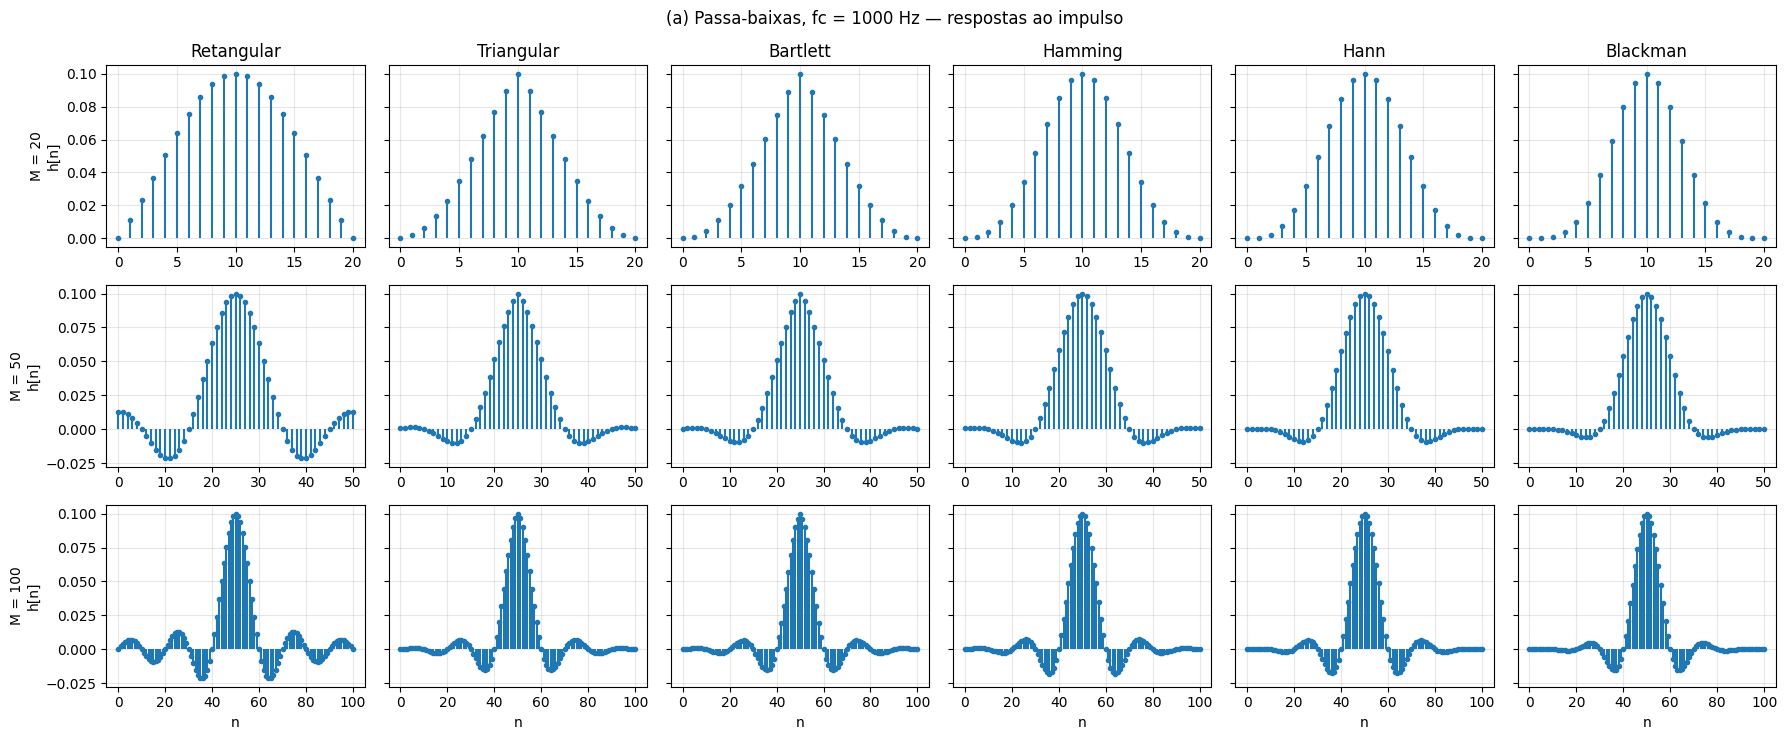

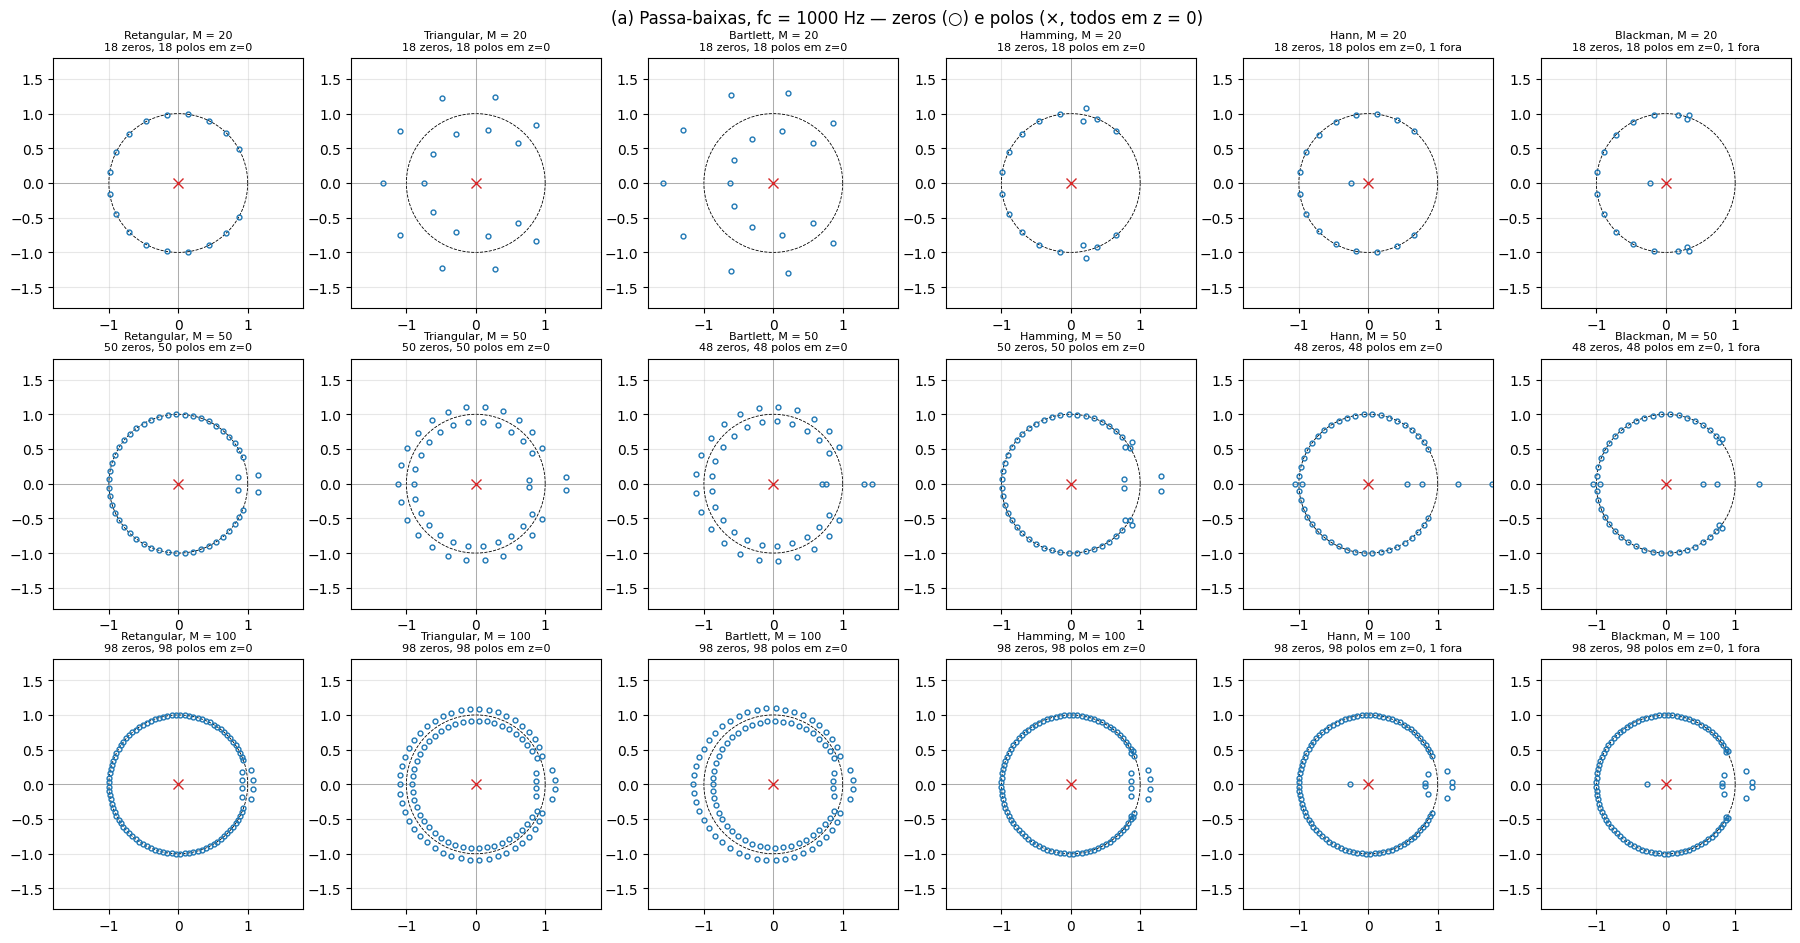

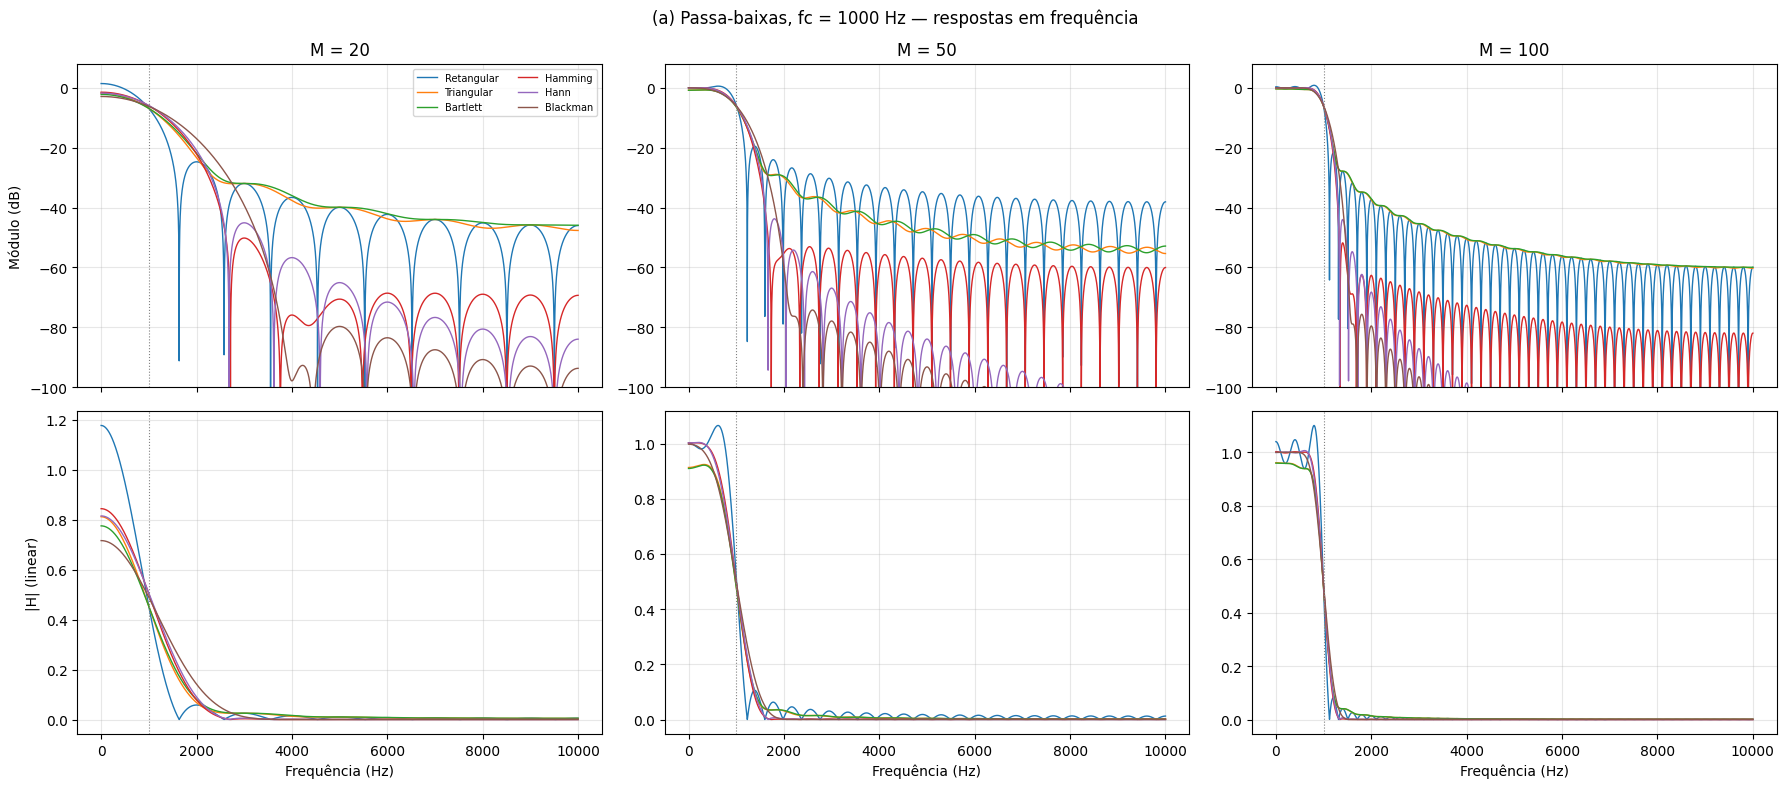

In [ ]:
medidas_a = imprimir_tabelas_q1("a")
figura_impulso("a"); figura_polos_zeros("a"); figura_resposta("a")

### (b) Passa-altas, $f_c = 2000$ Hz

=== (b) Passa-altas, fc = 2000 Hz ===
janela      | M=20 : Rp (dB)   As (dB)  |H(fc)| (dB) | M=50 : Rp (dB)   As (dB)  |H(fc)| (dB) | M=100: Rp (dB)   As (dB)  |H(fc)| (dB)
Retangular  |    0.2       —       -5.7       |    0.2      26.7     -5.9       |    0.3      28.3     -5.9      
Triangular  |    0.2       —       -5.7       |    0.2      27.1     -5.9       |    0.3      28.4     -5.9      
Bartlett    |    0.2       —       -5.7       |    0.2      26.4     -5.9       |    0.3      28.0     -5.9      
Hamming     |    0.0       —       -6.0       |    0.0      52.5     -6.0       |    0.0      55.3     -6.0      
Hann        |    0.0       —       -6.0       |    0.0      54.0     -6.0       |    0.0      54.6     -6.0      
Blackman    |    0.0       —       -6.0       |    0.0      72.3     -6.0       |    0.0      75.1     -6.0      


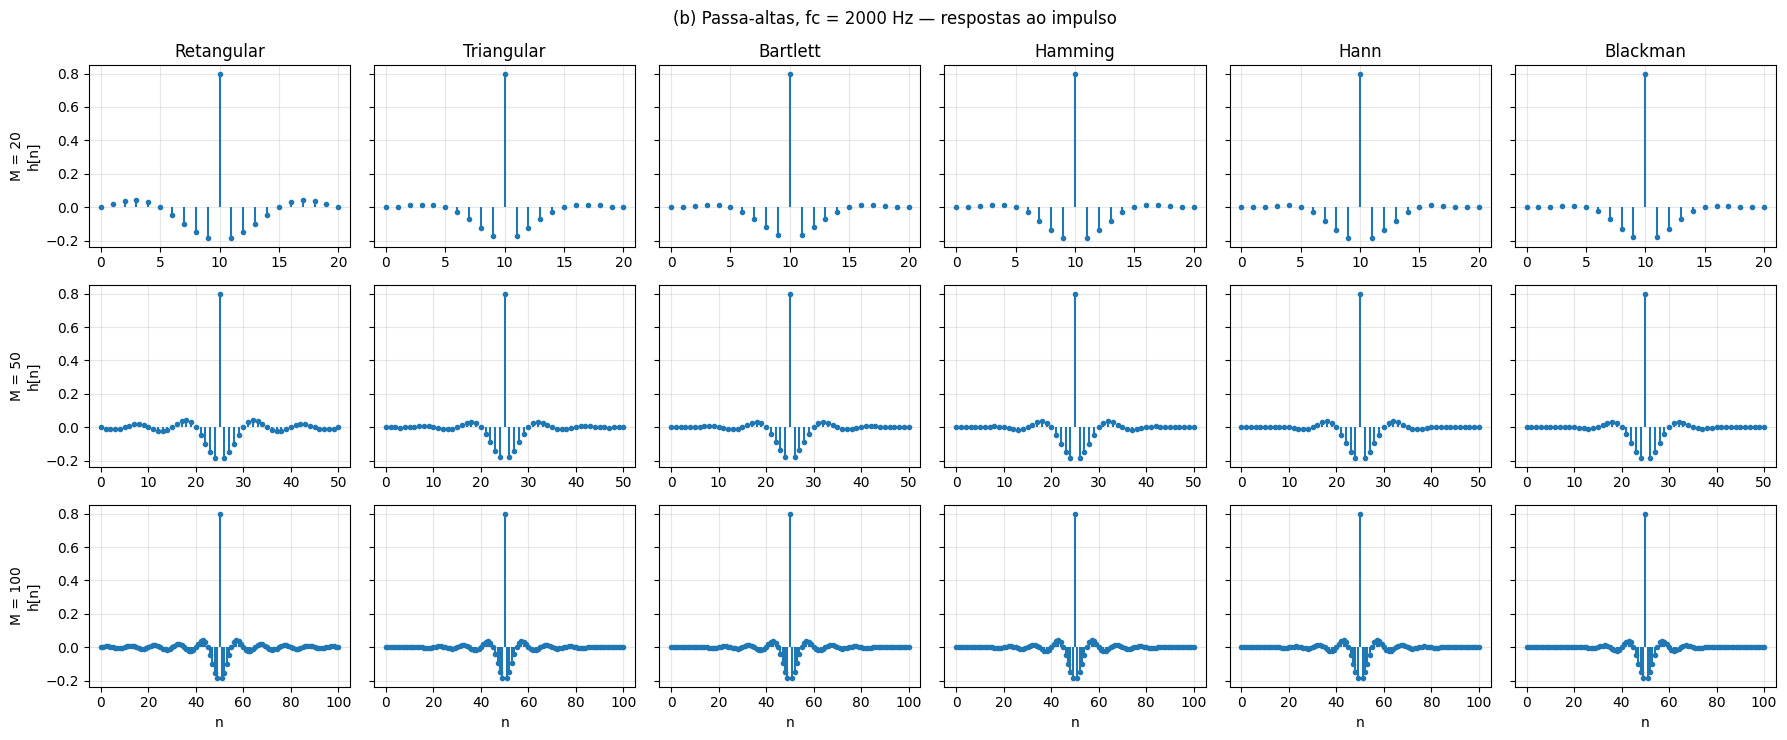

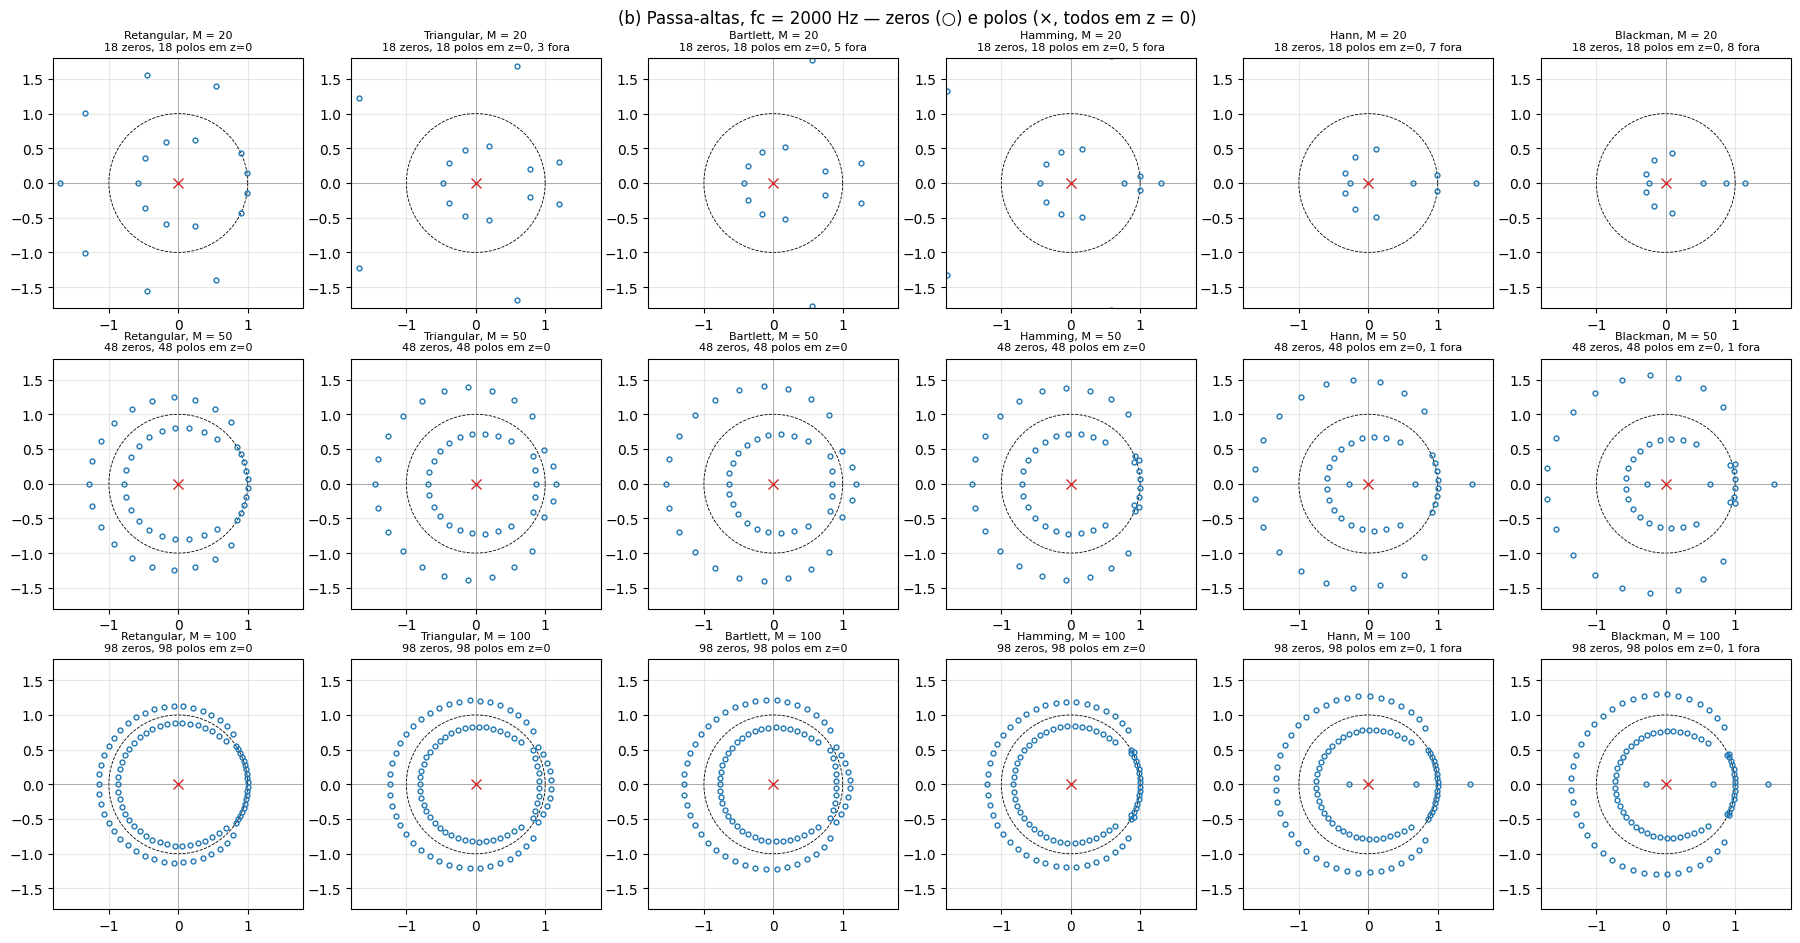

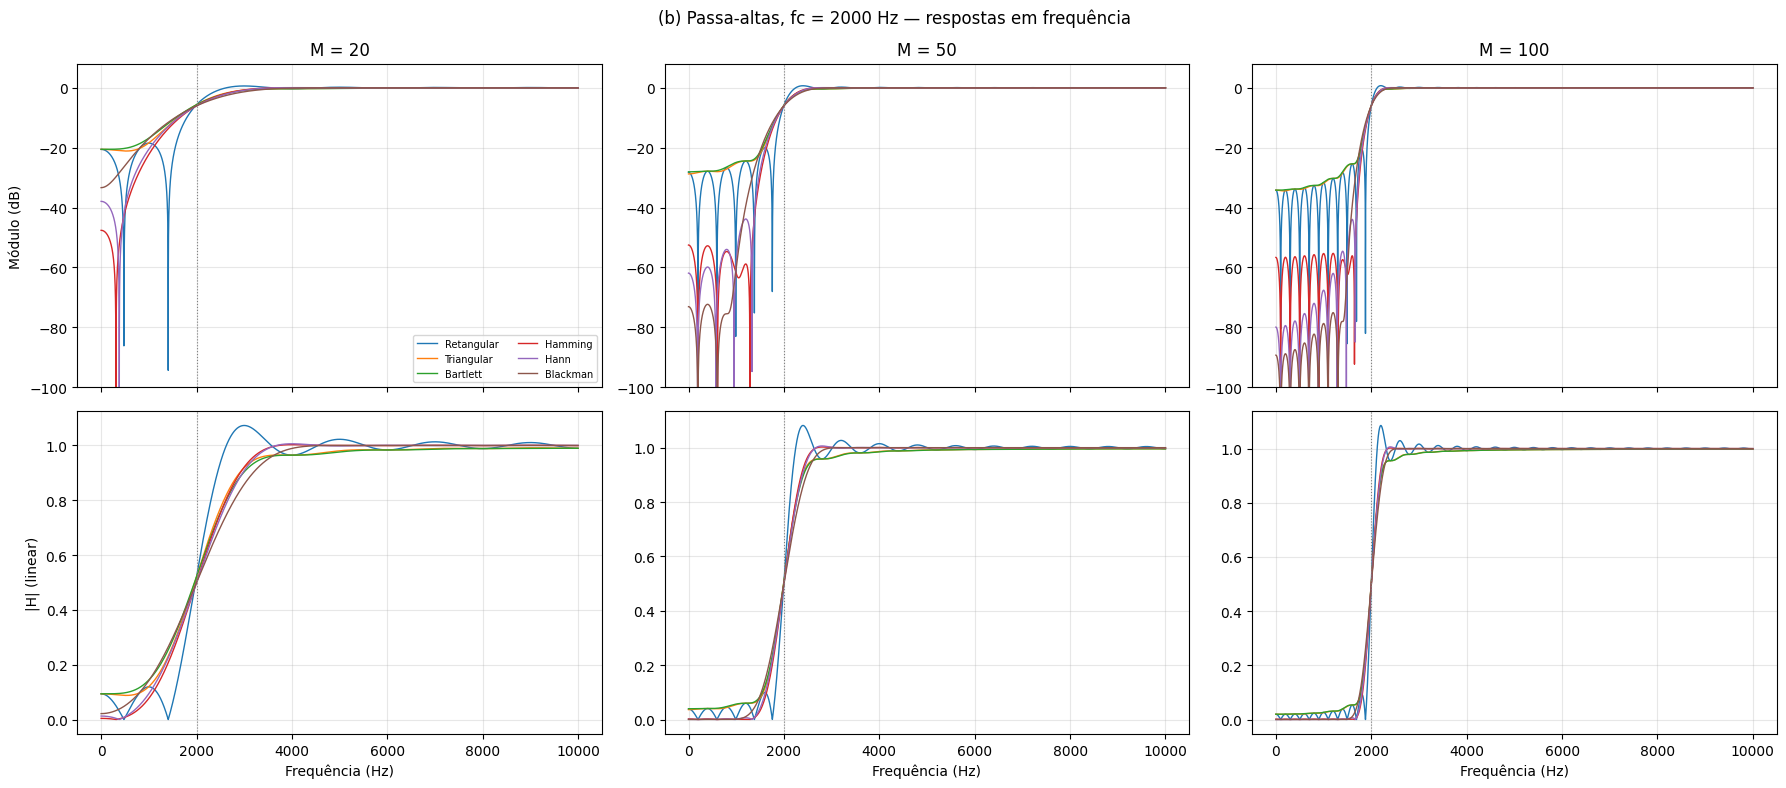

In [ ]:
medidas_b = imprimir_tabelas_q1("b")
figura_impulso("b"); figura_polos_zeros("b"); figura_resposta("b")

### (c) Passa-faixas, $f_{c1} = 500$ Hz, $f_{c2} = 2000$ Hz

=== (c) Passa-faixas, fc1 = 500 Hz, fc2 = 2000 Hz ===
janela      | M=20 : Rp (dB)   As (dB)  |H(fc)| (dB) | M=50 : Rp (dB)   As (dB)  |H(fc)| (dB) | M=100: Rp (dB)   As (dB)  |H(fc)| (dB)
Retangular  |    —        31.1     -7.6/ -6.7 |    —        35.6     -6.6/ -6.4 |    0.5      32.6     -6.4/ -6.2
Triangular  |    —        36.7     -5.9/ -6.6 |    —        33.4     -6.0/ -6.3 |    0.5      31.7     -6.0/ -6.2
Bartlett    |    —        36.2     -5.8/ -6.6 |    —        32.8     -5.9/ -6.3 |    0.5      31.4     -6.0/ -6.2
Hamming     |    —        51.0     -4.9/ -6.3 |    —        58.0     -6.1/ -6.0 |    0.0      57.9     -6.0/ -6.0
Hann        |    —        54.4     -4.7/ -6.2 |    —        55.0     -6.0/ -6.0 |    0.0      54.6     -6.0/ -6.0
Blackman    |    —        72.9     -4.6/ -6.9 |    —        75.9     -6.0/ -6.0 |    0.0      75.3     -6.0/ -6.0


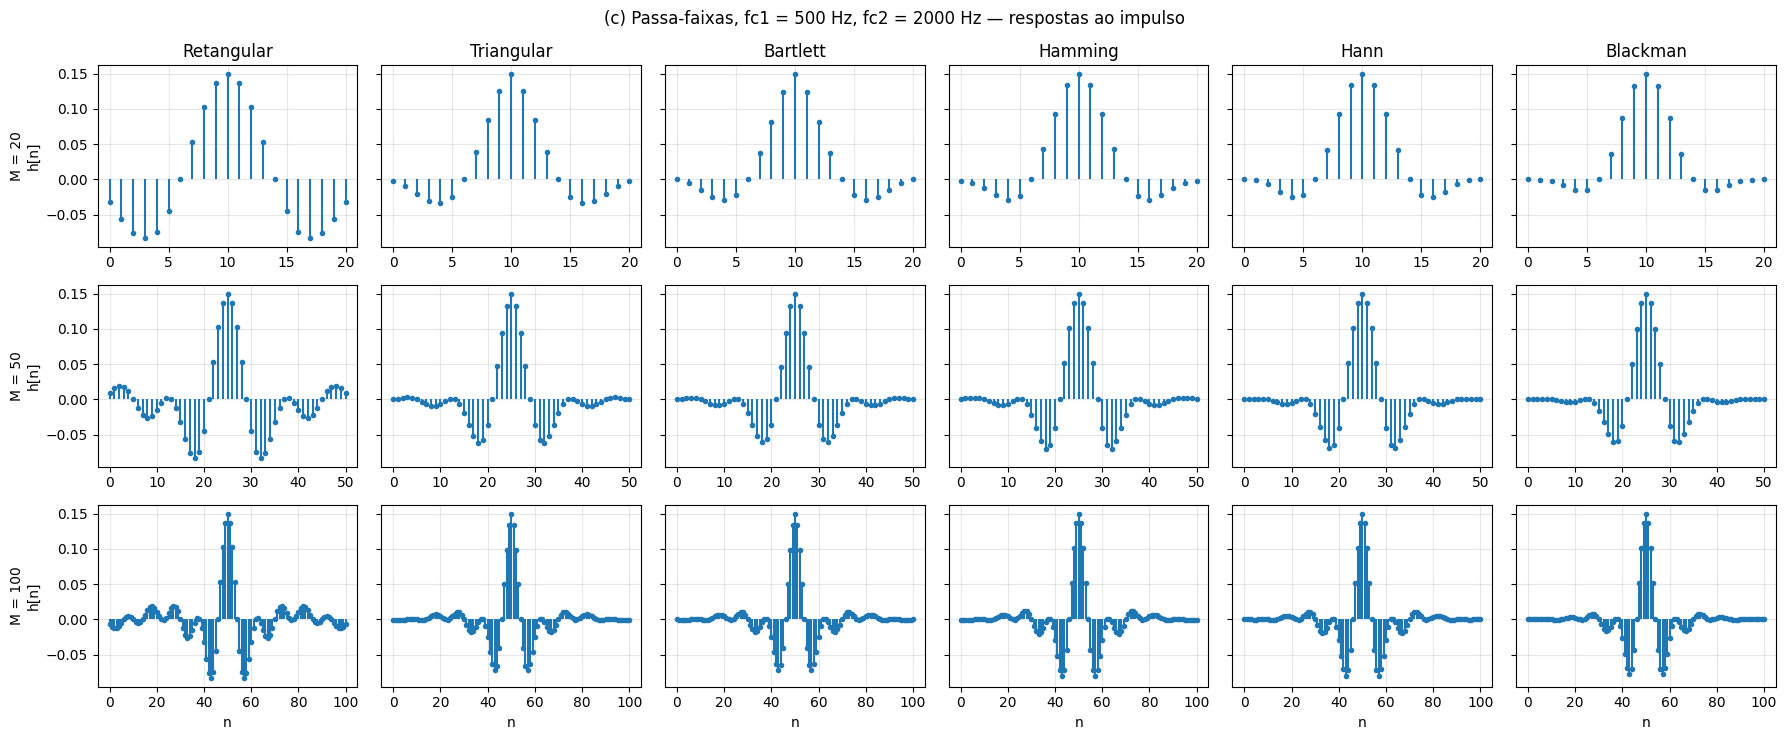

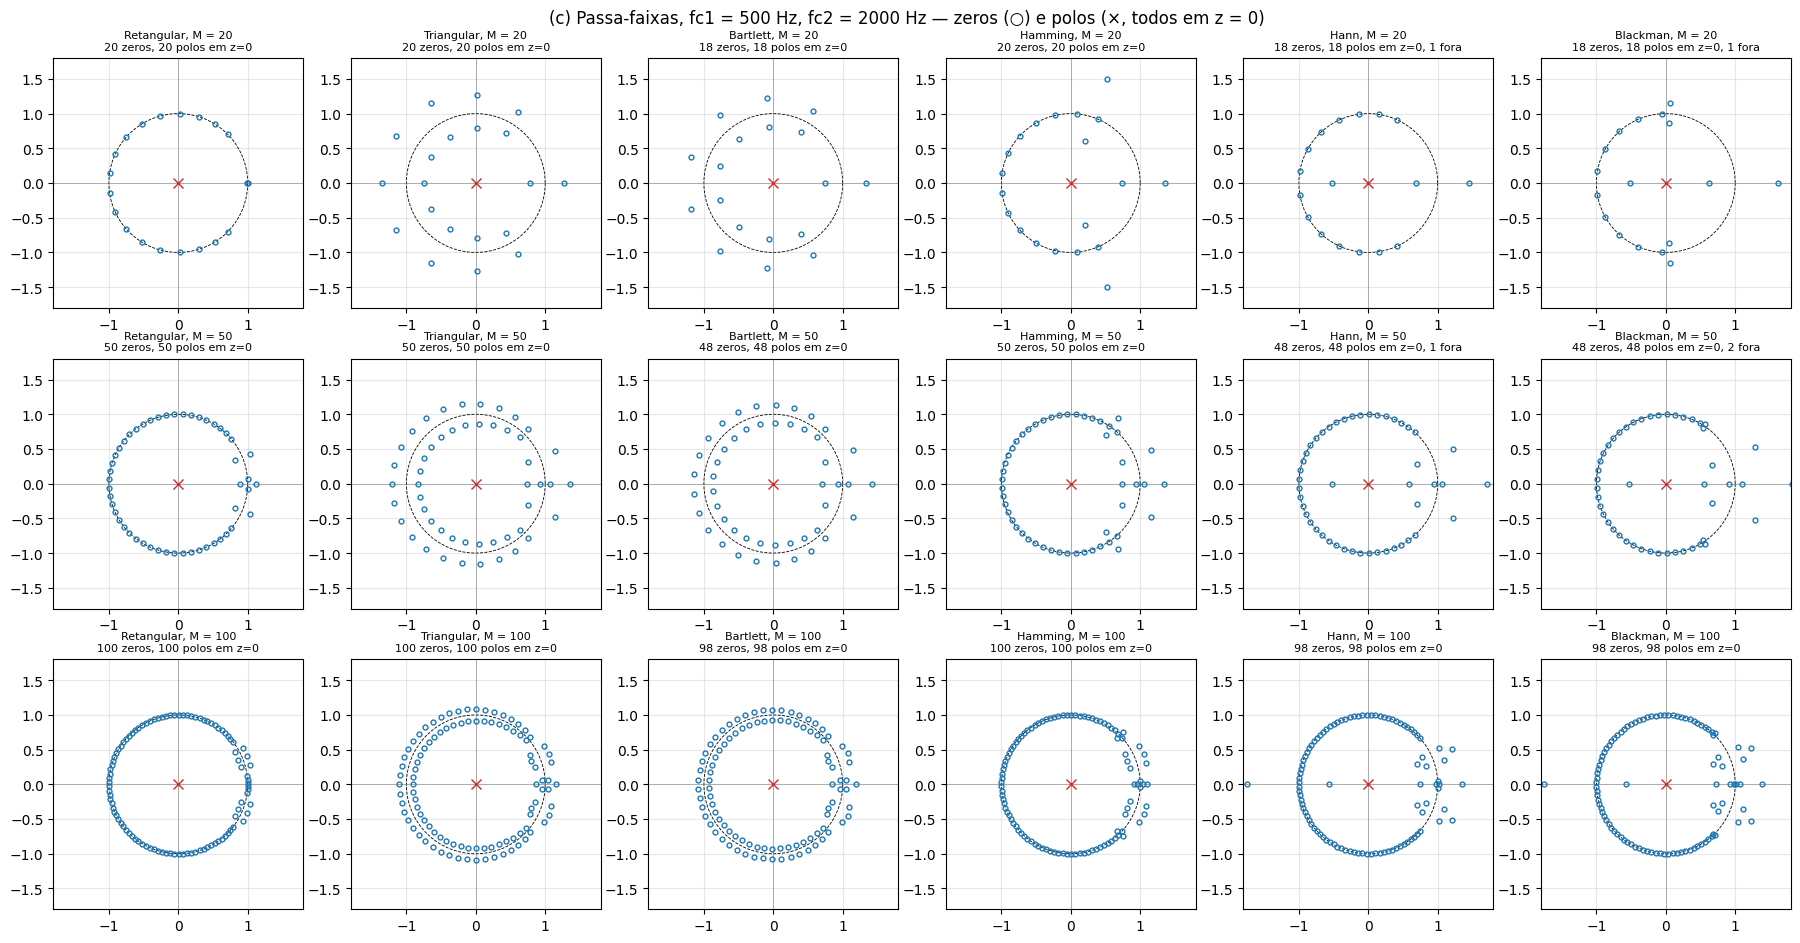

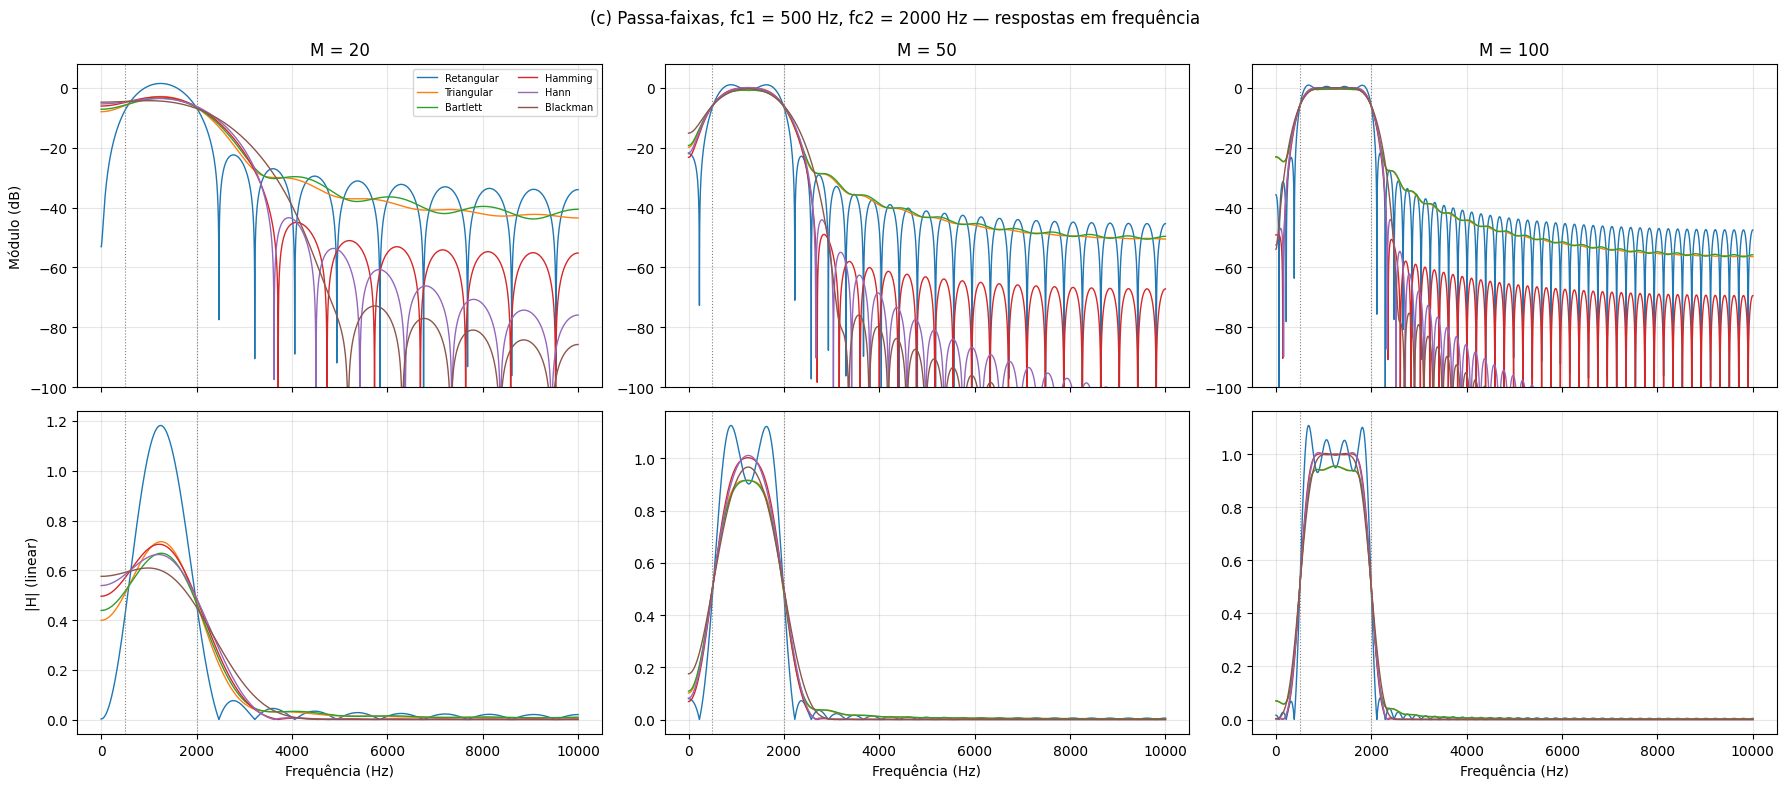

In [ ]:
medidas_c = imprimir_tabelas_q1("c")
figura_impulso("c"); figura_polos_zeros("c"); figura_resposta("c")

### (d) Rejeita-faixas, $f_{c1} = 1000$ Hz, $f_{c2} = 2500$ Hz

=== (d) Rejeita-faixas, fc1 = 1000 Hz, fc2 = 2500 Hz ===
janela      | M=20 : Rp (dB)   As (dB)  |H(fc)| (dB) | M=50 : Rp (dB)   As (dB)  |H(fc)| (dB) | M=100: Rp (dB)   As (dB)  |H(fc)| (dB)
Retangular  |    0.4       —       -6.6/ -6.5 |    0.1       —       -5.5/ -5.6 |    0.4      30.1     -6.1/ -6.1
Triangular  |    0.1       —       -5.6/ -5.3 |    0.2       —       -5.7/ -5.7 |    0.3      25.4     -5.9/ -5.8
Bartlett    |    0.1       —       -5.5/ -5.2 |    0.2       —       -5.7/ -5.7 |    0.3      25.1     -5.9/ -5.8
Hamming     |    0.0       —       -5.8/ -5.9 |    0.0       —       -6.0/ -6.0 |    0.0      55.9     -6.0/ -6.0
Hann        |    0.0       —       -5.7/ -5.8 |    0.0       —       -6.0/ -6.0 |    0.0      55.2     -6.0/ -6.0
Blackman    |    0.0       —       -5.4/ -5.2 |    0.0       —       -6.0/ -6.0 |    0.0      72.5     -6.0/ -6.0


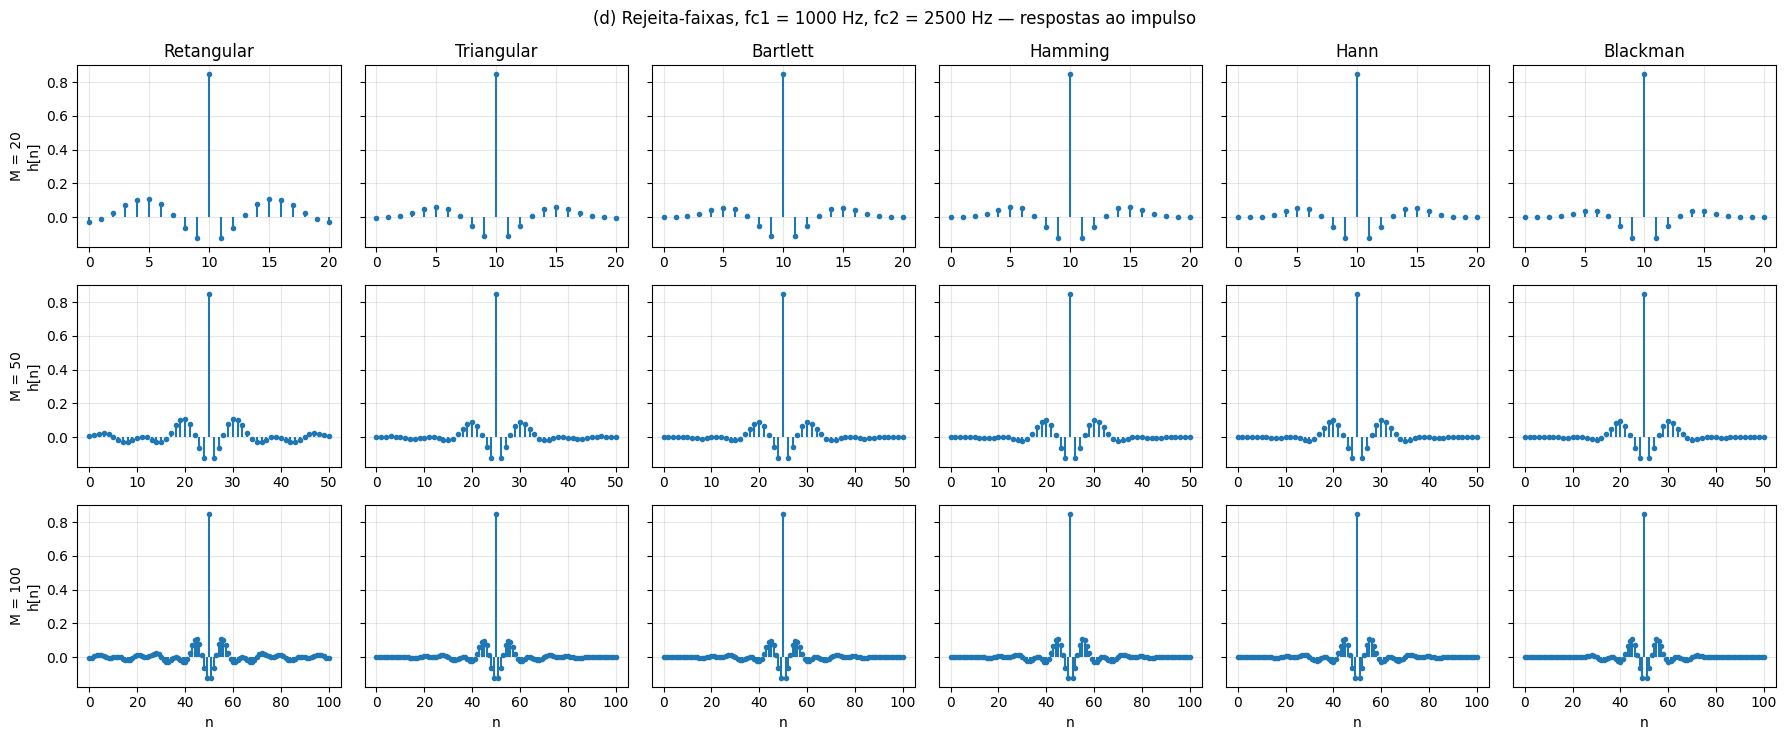

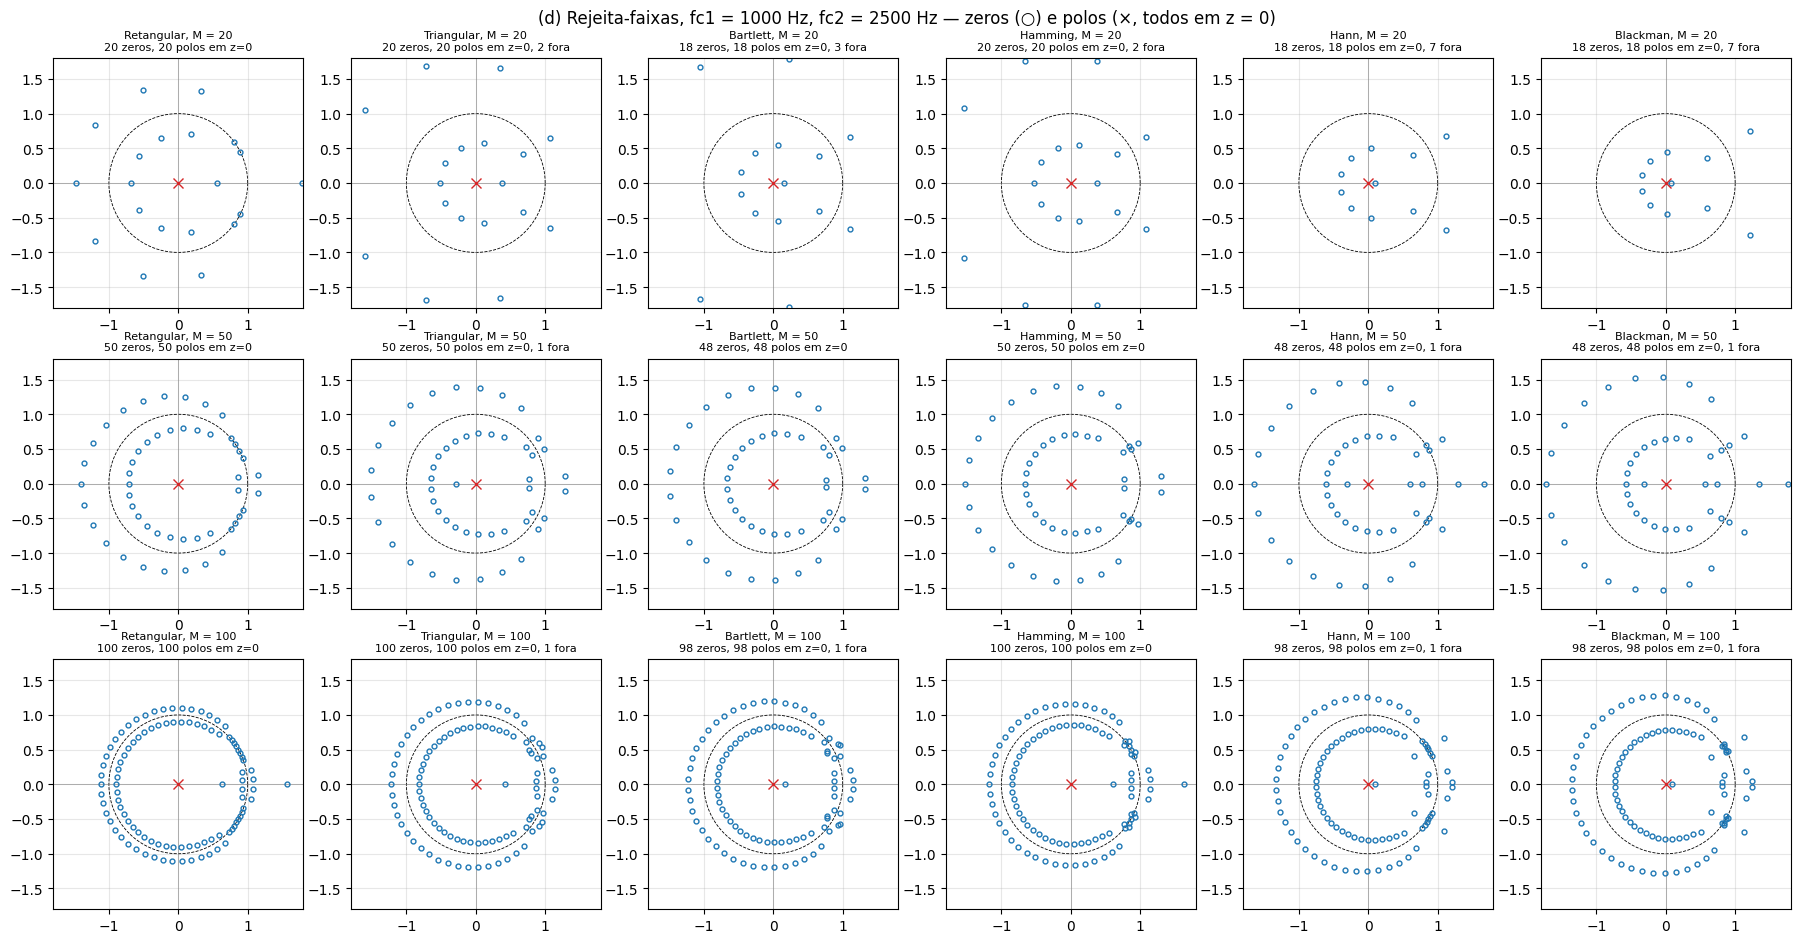

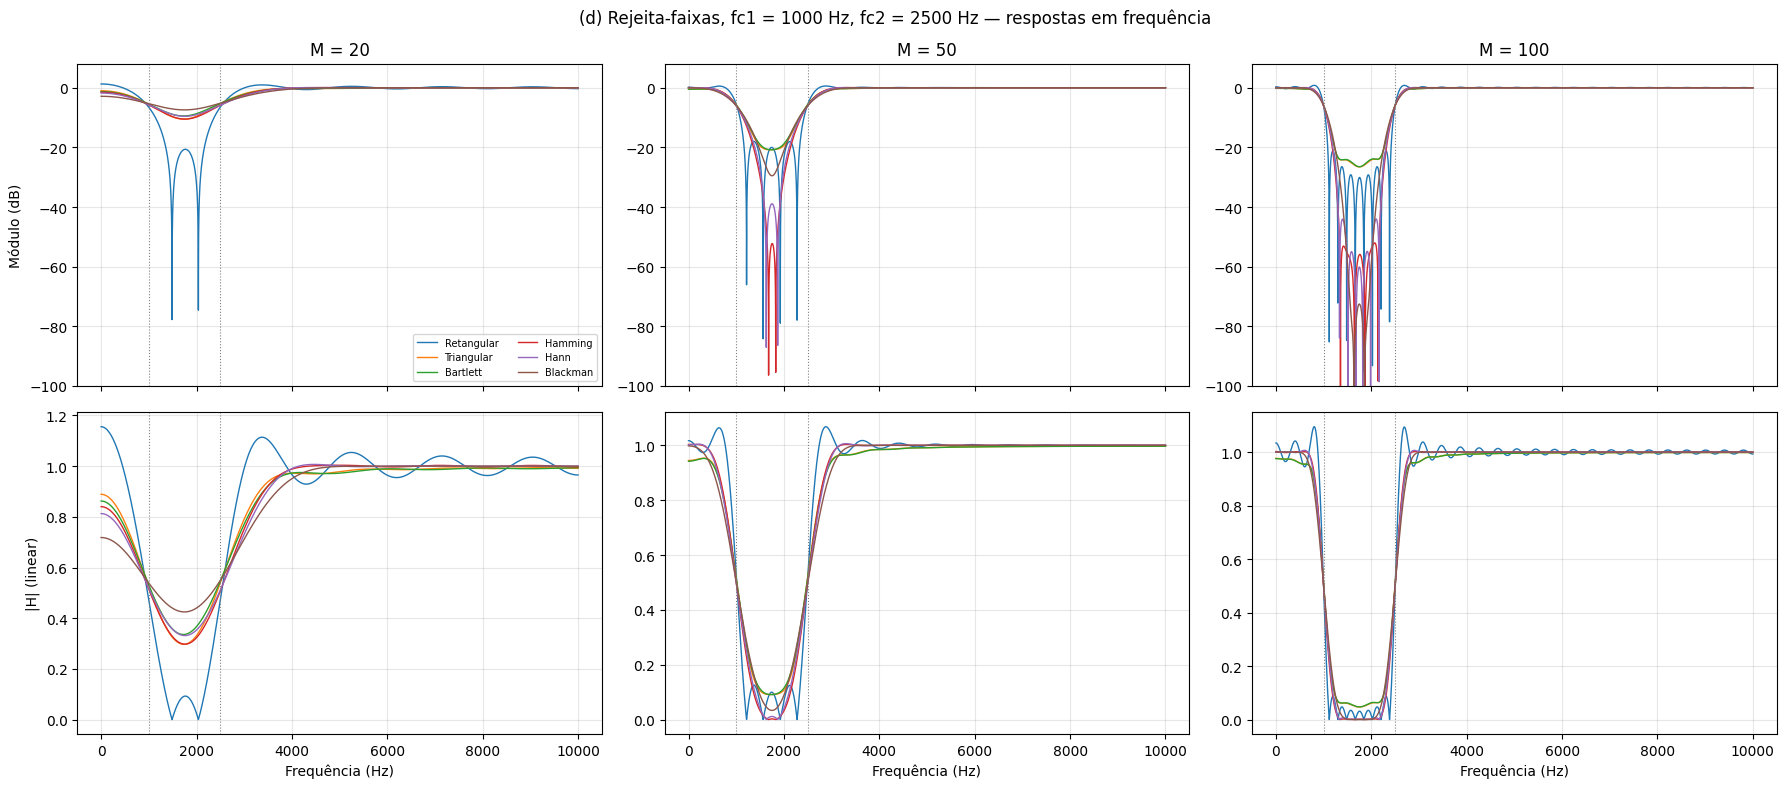

In [ ]:
medidas_d = imprimir_tabelas_q1("d")
figura_impulso("d"); figura_polos_zeros("d"); figura_resposta("d")

### Fase linear (verificação)

Retangular : atraso estimado na banda de passagem = 25.000 amostras (esperado M/2 = 25)
Triangular : atraso estimado na banda de passagem = 25.000 amostras (esperado M/2 = 25)
Bartlett   : atraso estimado na banda de passagem = 25.000 amostras (esperado M/2 = 25)
Hamming    : atraso estimado na banda de passagem = 25.000 amostras (esperado M/2 = 25)
Hann       : atraso estimado na banda de passagem = 25.000 amostras (esperado M/2 = 25)
Blackman   : atraso estimado na banda de passagem = 25.000 amostras (esperado M/2 = 25)


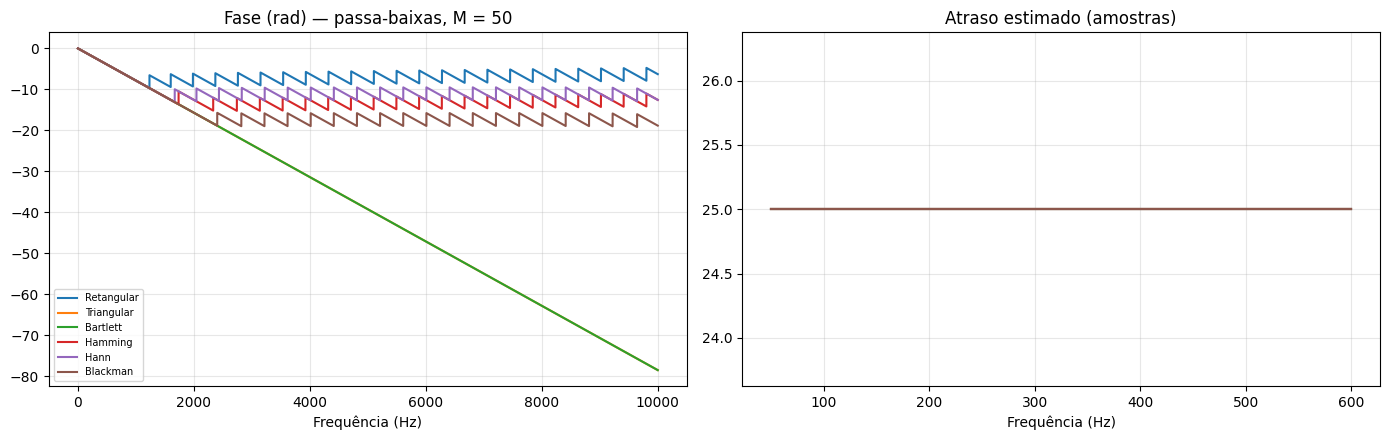

In [ ]:
# Fase da resposta do passa-baixas (a), M = 50: linear com inclinação -M/2 amostras (atraso constante)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
for nome in NOMES_JANELAS:
    h = projetos_q1[("a", 50, nome)]
    f, H = resposta_frequencia(h, FS)
    w = 2 * np.pi * f / FS
    fase = np.unwrap(np.angle(H))
    ax1.plot(f, fase, color=CORES_J[nome], label=nome)
    # estimativa do atraso na banda de passagem (derivada da fase)
    sel = (f > 50) & (f < 600)
    atraso = -np.polyfit(w[sel], fase[sel], 1)[0]
    ax2.plot(f[sel], np.full(sel.sum(), atraso), color=CORES_J[nome])
    print(f"{nome:<11}: atraso estimado na banda de passagem = {atraso:.3f} amostras (esperado M/2 = 25)")
ax1.set_title("Fase (rad) — passa-baixas, M = 50"); ax1.set_xlabel("Frequência (Hz)"); ax1.grid(True, alpha=0.3); ax1.legend(fontsize=7)
ax2.set_title("Atraso estimado (amostras)"); ax2.set_xlabel("Frequência (Hz)"); ax2.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### Leitura dos resultados (Questão 1)

- **Todos os filtros são estáveis e de fase linear:** os $M$ polos ficam em $z=0$ e $h[n]=h[M-n]$ (atraso de grupo $M/2$).
  Os zeros aparecem em pares conjugados e em pares recíprocos ($z_k$ e $1/z_k^*$), por causa da simetria dos coeficientes.
- **Ordem $M$:** controla a **largura da transição** ($\propto 1/M$). A guarda de $\pm3f_s/M$ Hz consome a banda correspondente e a medida fica indefinida (“—”):
  com $M=20$ isso ocorre em todos os filtros (a guarda é de 3000 Hz), e com $M=50$ ainda ocorre em $R_p$ de (a) e (c) e em $A_s$ de (d). Nesses casos o filtro não resolve a especificação.
- **Janela:** controla o compromisso **transição × atenuação**. A retangular tem a transição mais estreita, mas a pior atenuação
  (≈ 27–36 dB medidos fora da guarda, que exclui o primeiro lobo lateral de ≈ −21 dB) e uma ondulação na banda de passagem
  ($R_p\approx0{,}3$–$0{,}5$ dB para $M=100$) que **não** diminui ao aumentar $M$ (Gibbs). Triangular/Bartlett ficam em ≈ 25–34 dB;
  Hamming e Hann em ≈ 52–62 dB e Blackman em ≈ 72–76 dB (com $M\ge50$), em troca de uma transição mais larga.
  A atenuação depende da janela e **não** de $M$; $M$ só estreita a transição.
- **Janelas com extremos nulos** (Bartlett, Hann e Blackman): os coeficientes das pontas valem zero, e o polinômio efetivo tem $M-2$ zeros
  (o título de cada diagrama de polos e zeros indica a contagem).
- **Ganho em $f_c$:** ≈ −6 dB (entre −5,5 e −6,6 dB para $M\ge50$), característica do método das janelas.
- **Fase linear:** o atraso estimado na banda de passagem é exatamente $M/2$ amostras para todas as janelas (célula “Fase linear”).

## Questão 2 — Filtros a partir de respostas de módulo desenhadas

Para cada módulo $|H(e^{j\omega})|$ do enunciado, a resposta ao impulso ideal (fase nula, real e par) é
$$h_d[n]=\frac{1}{2\pi}\int_{-\pi}^{\pi}H_d(\omega)\,e^{j\omega n}\,d\omega=\frac{1}{\pi}\int_{0}^{\pi}H_d(\omega)\cos(\omega n)\,d\omega .$$

**(a)** $H_d=2$ para $|\omega|<\pi/6$, $H_d=1$ para $\pi/6<|\omega|<\pi/3$ e $0$ no restante. Somando os dois retângulos
(o primeiro vale $2\,\mathrm{rect}$ até $\pi/6$ e o segundo vale $1$ entre $\pi/6$ e $\pi/3$):
$$h_d[n]=\frac{\sin(\pi n/6)+\sin(\pi n/3)}{\pi n},\qquad h_d[0]=\tfrac12 .$$

**(b)** Triângulo $H_d=1-\dfrac{|\omega|}{2\omega_c}$ para $|\omega|<2\omega_c$ e $0$ no restante (o enunciado não fixa $\omega_c$;
adota-se $\omega_c=\pi/4$, parâmetro alterável abaixo). Integrando por partes:
$$h_d[n]=\frac{1-\cos(2\omega_c n)}{2\pi\,\omega_c\,n^2}=\frac{\omega_c}{\pi}\left[\frac{\sin(\omega_c n)}{\omega_c n}\right]^2,\qquad h_d[0]=\frac{\omega_c}{\pi}.$$

**(c)** Rampa de $0$ a $1$ em $[0,\pi/4]$, patamar $1$ em $[\pi/4,\pi/2]$ e $0$ em $[\pi/2,\pi]$ (simétrico em $-\omega$):
$$h_d[n]=\frac{1}{\pi}\left[\frac{\sin(\pi n/2)}{n}+\frac{4}{\pi}\,\frac{\cos(\pi n/4)-1}{n^2}\right],\qquad h_d[0]=\tfrac38 .$$

Projeto: $h[n]=h_d[n-\alpha]\,w[n]$, $\alpha=M/2$, com $M\in\{50,100\}$ e janelas retangular, triangular, Hamming, Hann e Blackman.
Como não há $f_s$ no enunciado, o eixo de frequências é $\omega/\pi$. As fórmulas fechadas são **validadas** abaixo por integração numérica
(regra do trapézio escrita aqui) do $h_d[n]$.

In [ ]:
ORDENS_Q2 = [50, 100]
JANELAS_Q2 = ["Retangular", "Triangular", "Hamming", "Hann", "Blackman"]
WC_2B = np.pi / 4          # parâmetro do item (b): o triângulo vai de -2*wc a 2*wc

def _m(M):
    return np.arange(M + 1) - M / 2

def hd_2a(M):
    m = _m(M)
    return (np.pi / 6 / np.pi) * np.sinc((np.pi / 6) * m / np.pi) + (np.pi / 3 / np.pi) * np.sinc((np.pi / 3) * m / np.pi)

def hd_2b(M, wc=WC_2B):
    m = _m(M)
    return (wc / np.pi) * np.sinc(wc * m / np.pi) ** 2

def hd_2c(M):
    m = _m(M)
    mm = np.where(m == 0, 1.0, m)                     # evita 0/0; em m = 0 usa-se o limite 3/8
    h = (np.sin(np.pi * mm / 2) / mm + (4 / np.pi) * (np.cos(np.pi * mm / 4) - 1) / mm ** 2) / np.pi
    return np.where(m == 0, 3.0 / 8.0, h)

# Módulos ideais (0 <= w <= pi)
def Hd_2a(w): return np.where(w < np.pi / 6, 2.0, np.where(w < np.pi / 3, 1.0, 0.0))
def Hd_2b(w, wc=WC_2B): return np.maximum(0.0, 1 - w / (2 * wc))
def Hd_2c(w): return np.where(w < np.pi / 4, w / (np.pi / 4), np.where(w < np.pi / 2, 1.0, 0.0))

FILTROS_Q2 = {
    "a": (hd_2a, Hd_2a, [np.pi / 6, np.pi / 3], "(a) Dois degraus: 2 até π/6 e 1 até π/3"),
    "b": (hd_2b, Hd_2b, [],                     "(b) Triângulo de −2ωc a 2ωc (ωc = π/4)"),
    "c": (hd_2c, Hd_2c, [np.pi / 2],            "(c) Rampa até π/4, patamar até π/2"),
}

# --- Validação: integral numérica (trapézio próprio) x fórmula fechada ---
def trapezio(y, dx):
    return np.sum((y[1:] + y[:-1]) / 2.0) * dx

w_grade = np.linspace(0, np.pi, 400001)
for item, (hd_fn, Hd_fn, _, titulo) in FILTROS_Q2.items():
    M = 100
    m = _m(M)
    Hv = Hd_fn(w_grade)
    h_num = np.array([trapezio(Hv * np.cos(w_grade * mi), w_grade[1] - w_grade[0]) / np.pi for mi in m])
    print(f"{titulo}: erro máx |h_fechada - h_numérica| = {np.max(np.abs(hd_fn(M) - h_num)):.2e}")
    assert np.max(np.abs(hd_fn(M) - h_num)) < 2e-4

(a) Dois degraus: 2 até π/6 e 1 até π/3: erro máx |h_fechada - h_numérica| = 8.33e-07
(b) Triângulo de −2ωc a 2ωc (ωc = π/4): erro máx |h_fechada - h_numérica| = 2.08e-12
(c) Rampa até π/4, patamar até π/2: erro máx |h_fechada - h_numérica| = 1.25e-06


In [ ]:
projetos_q2 = {(item, M, nome): FILTROS_Q2[item][0](M) * JANELAS[nome](M)
               for item in FILTROS_Q2 for M in ORDENS_Q2 for nome in JANELAS_Q2}

def figura_impulso_q2(item):
    titulo = FILTROS_Q2[item][3]
    fig, eixos = plt.subplots(len(ORDENS_Q2), len(JANELAS_Q2), figsize=(17, 5.5), sharex="row", sharey="row")
    for i, M in enumerate(ORDENS_Q2):
        for j, nome in enumerate(JANELAS_Q2):
            ax = eixos[i, j]
            ax.stem(np.arange(M + 1), projetos_q2[(item, M, nome)], basefmt=" ", markerfmt=".", linefmt="C0-")
            ax.grid(True, alpha=0.3)
            if i == 0: ax.set_title(nome)
            if j == 0: ax.set_ylabel(f"M = {M}\nh[n]")
            if i == len(ORDENS_Q2) - 1: ax.set_xlabel("n")
    fig.suptitle(f"{titulo} — respostas ao impulso")
    plt.tight_layout(); plt.show()

def figura_pz_q2(item):
    titulo = FILTROS_Q2[item][3]
    fig, eixos = plt.subplots(len(ORDENS_Q2), len(JANELAS_Q2), figsize=(17, 7))
    for i, M in enumerate(ORDENS_Q2):
        for j, nome in enumerate(JANELAS_Q2):
            desenhar_pz(eixos[i, j], projetos_q2[(item, M, nome)], f"{nome}, M = {M}")
    fig.suptitle(f"{titulo} — zeros (○) e polos (×, todos em z = 0)")
    plt.tight_layout(); plt.show()

def figura_resposta_q2(item):
    hd_fn, Hd_fn, _, titulo = FILTROS_Q2[item]
    fig, eixos = plt.subplots(2, len(ORDENS_Q2), figsize=(15, 7.5), sharex=True)
    for j, M in enumerate(ORDENS_Q2):
        for nome in JANELAS_Q2:
            w, H = resposta_omega(projetos_q2[(item, M, nome)])
            eixos[0, j].plot(w / np.pi, em_db(H), color=CORES_J[nome], lw=1.0, label=nome)
            eixos[1, j].plot(w / np.pi, np.abs(H), color=CORES_J[nome], lw=1.0)
        wd = np.linspace(0, np.pi, 4000)
        eixos[1, j].plot(wd / np.pi, Hd_fn(wd), "k--", lw=1.0, label="ideal")
        eixos[0, j].set_ylim(-100, 12); eixos[0, j].set_title(f"M = {M}")
        eixos[1, j].set_xlabel("ω / π")
        for ax in eixos[:, j]: ax.grid(True, alpha=0.3)
    eixos[0, 0].set_ylabel("Módulo (dB)"); eixos[1, 0].set_ylabel("|H| (linear)")
    eixos[0, 0].legend(fontsize=7, ncol=2); eixos[1, 0].legend(fontsize=7, ncol=2)
    fig.suptitle(f"{titulo} — respostas em frequência (tracejado: ideal)")
    plt.tight_layout(); plt.show()

def tabela_erro_q2(item):
    # A(w) = Re{H e^{jwM/2}} é a resposta de amplitude (fase linear removida). Erro frente ao módulo ideal.
    hd_fn, Hd_fn, descont, titulo = FILTROS_Q2[item]
    print(f"=== {titulo} ===")
    print(f"{'janela':<11} | " + " | ".join(f"M={M:<3d}: erro RMS   erro máx (fora da guarda)" for M in ORDENS_Q2))
    for nome in JANELAS_Q2:
        col = []
        for M in ORDENS_Q2:
            w, H = resposta_omega(projetos_q2[(item, M, nome)])
            A = np.real(H * np.exp(1j * w * M / 2))
            e = A - Hd_fn(w)
            sel = np.ones(len(w), bool)
            for wd0 in descont:
                sel &= np.abs(w - wd0) > 6 * np.pi / M
            col.append(f"{np.sqrt(np.mean(e ** 2)):8.4f}   {np.max(np.abs(e[sel])):8.4f}".ljust(36))
        print(f"{nome:<11} | " + " | ".join(col))

### (a) Dois degraus

=== (a) Dois degraus: 2 até π/6 e 1 até π/3 ===
janela      | M=50 : erro RMS   erro máx (fora da guarda) | M=100: erro RMS   erro máx (fora da guarda)
Retangular  |   0.0889     0.0538                  |   0.0619     0.0353                 
Triangular  |   0.1251     0.0705                  |   0.0892     0.0518                 
Hamming     |   0.1163     0.0030                  |   0.0821     0.0021                 
Hann        |   0.1206     0.0022                  |   0.0853     0.0019                 
Blackman    |   0.1324     0.0003                  |   0.0936     0.0002                 


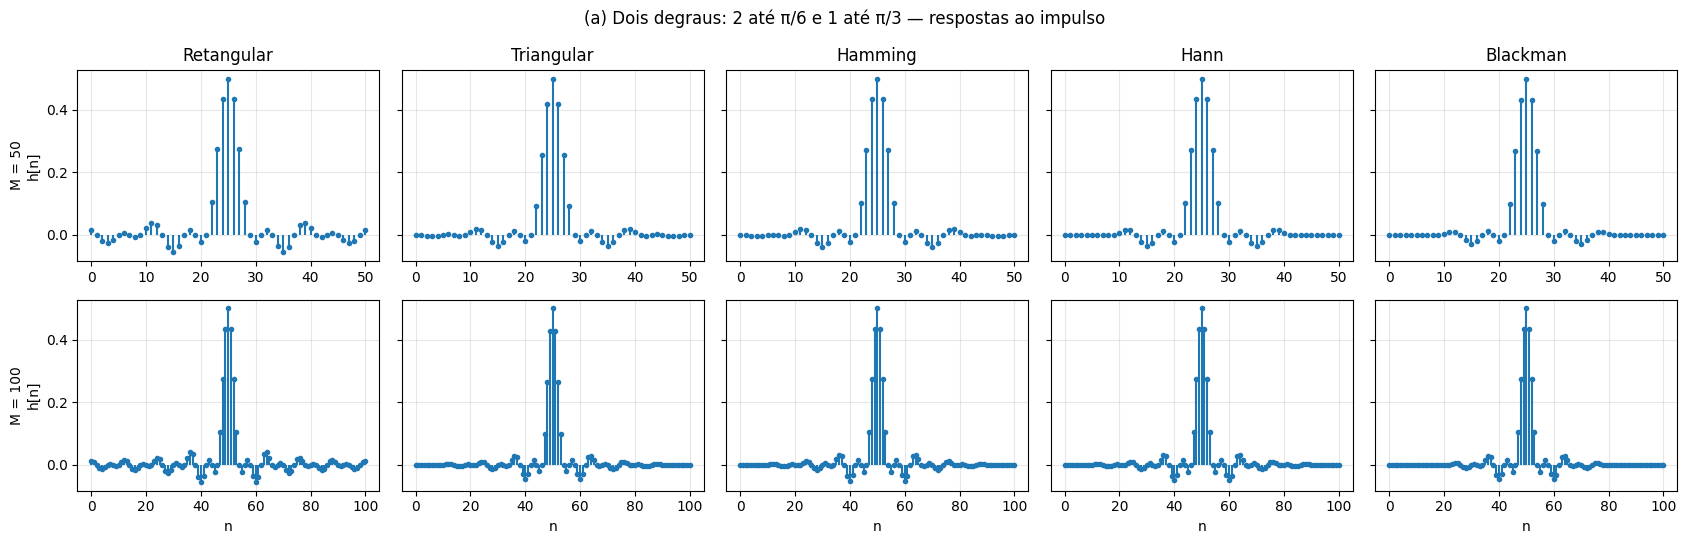

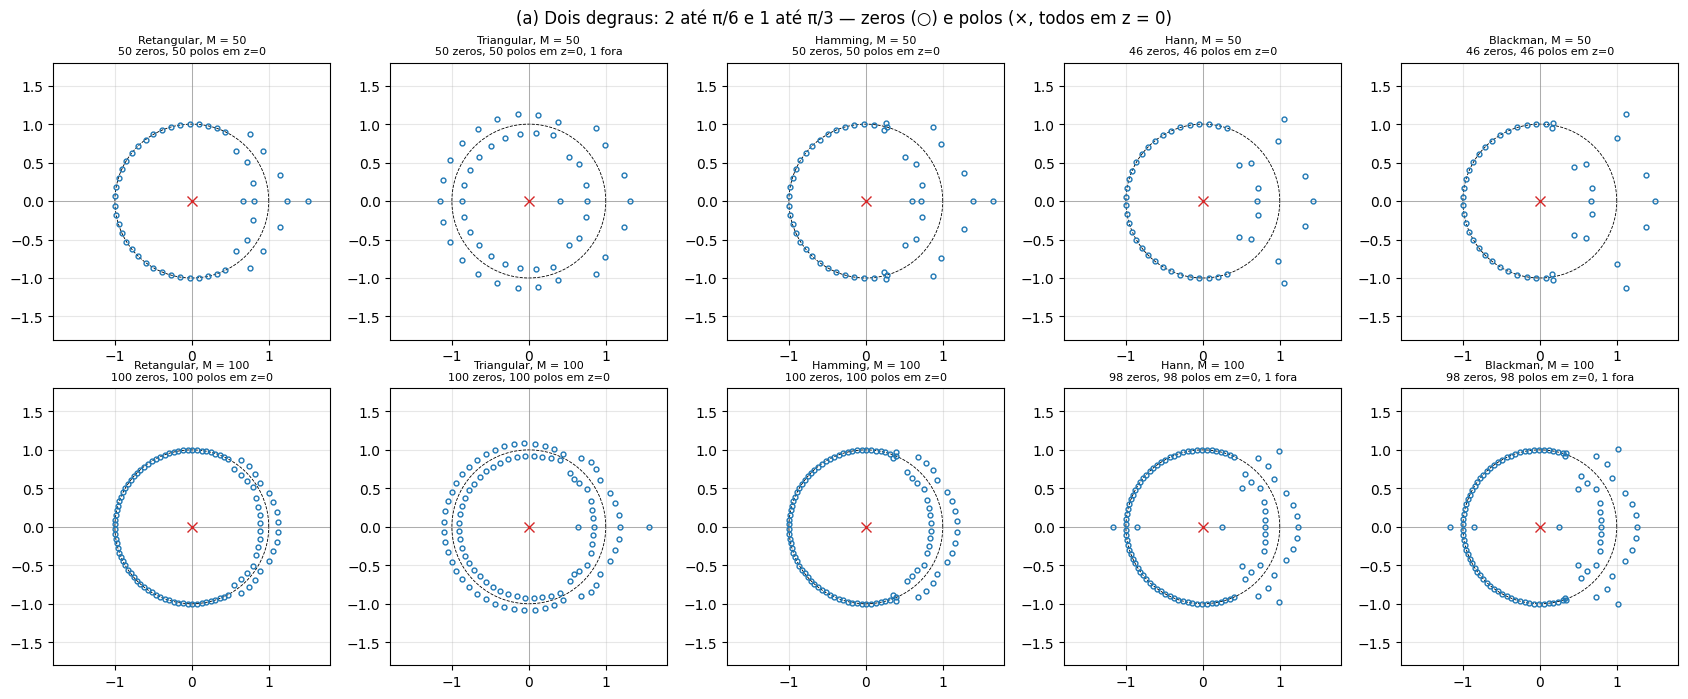

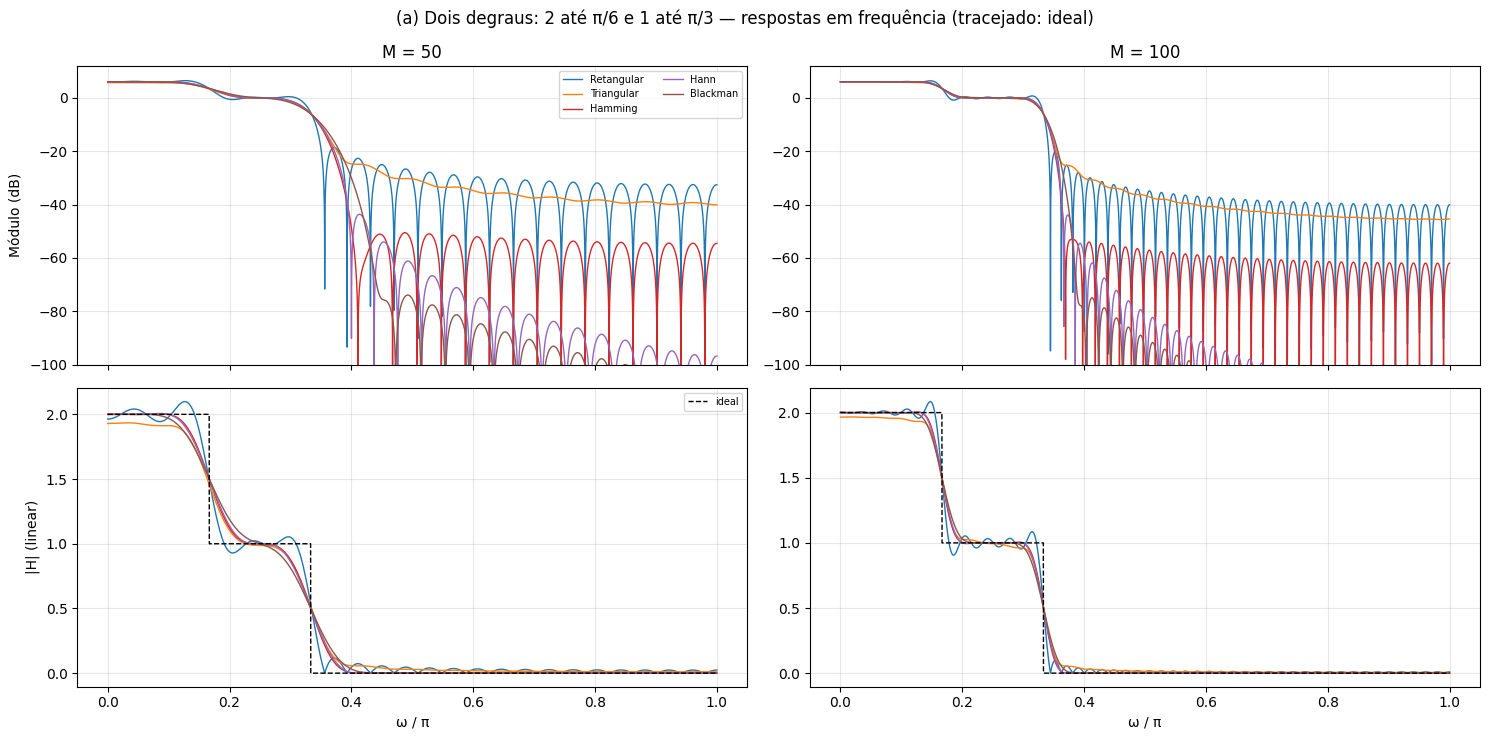

In [ ]:
tabela_erro_q2("a")
figura_impulso_q2("a"); figura_pz_q2("a"); figura_resposta_q2("a")

### (b) Triângulo

=== (b) Triângulo de −2ωc a 2ωc (ωc = π/4) ===
janela      | M=50 : erro RMS   erro máx (fora da guarda) | M=100: erro RMS   erro máx (fora da guarda)
Retangular  |   0.0017     0.0162                  |   0.0006     0.0079                 
Triangular  |   0.0172     0.0808                  |   0.0088     0.0465                 
Hamming     |   0.0053     0.0447                  |   0.0019     0.0223                 
Hann        |   0.0058     0.0472                  |   0.0020     0.0236                 
Blackman    |   0.0081     0.0587                  |   0.0029     0.0294                 


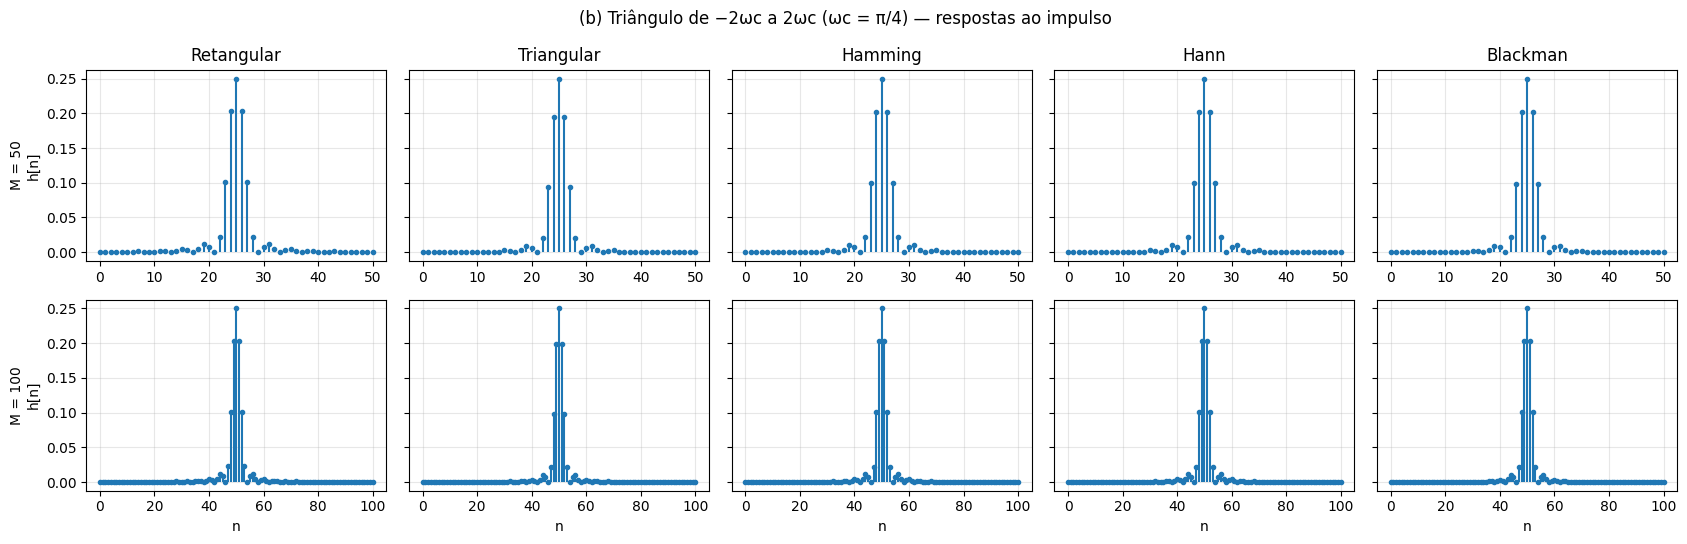

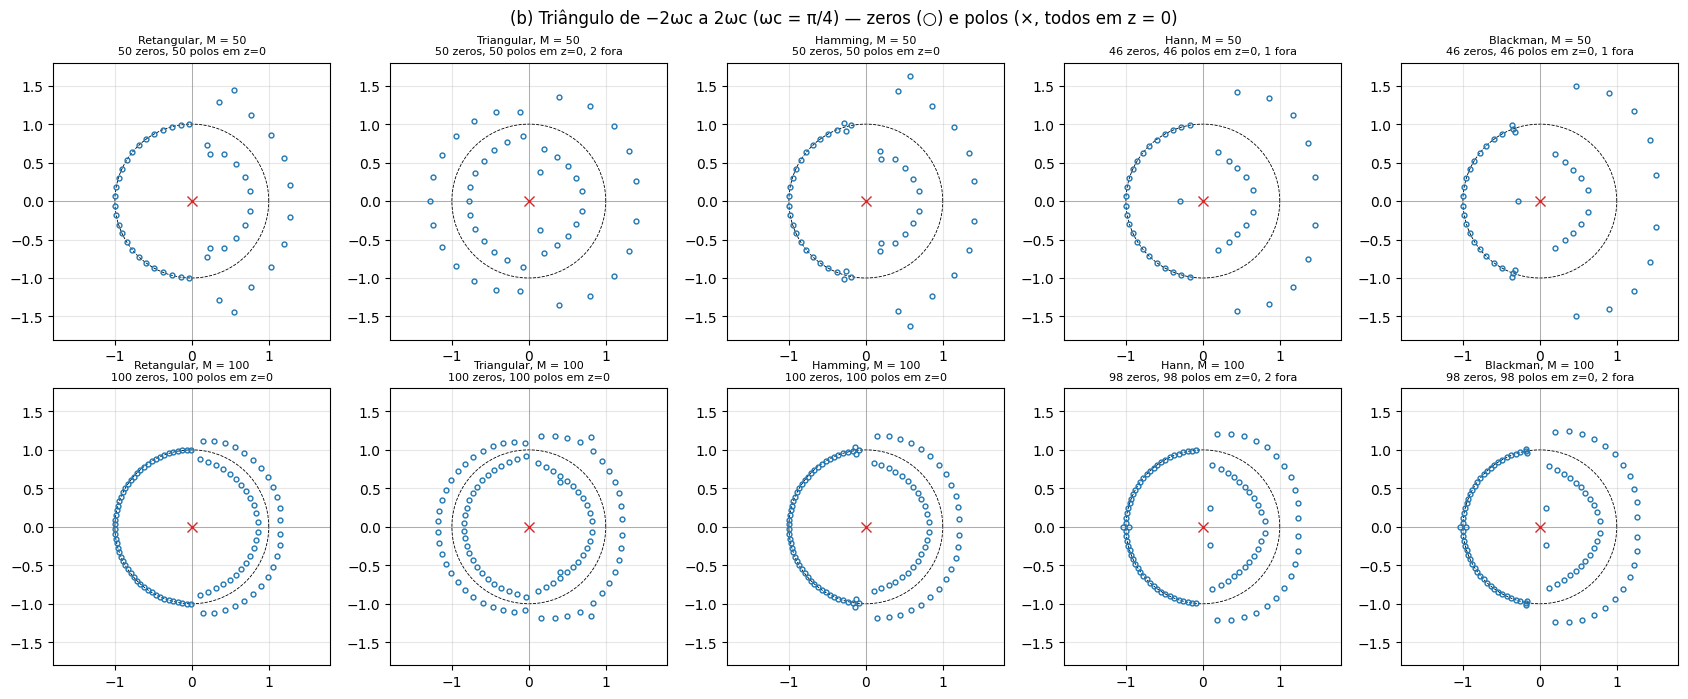

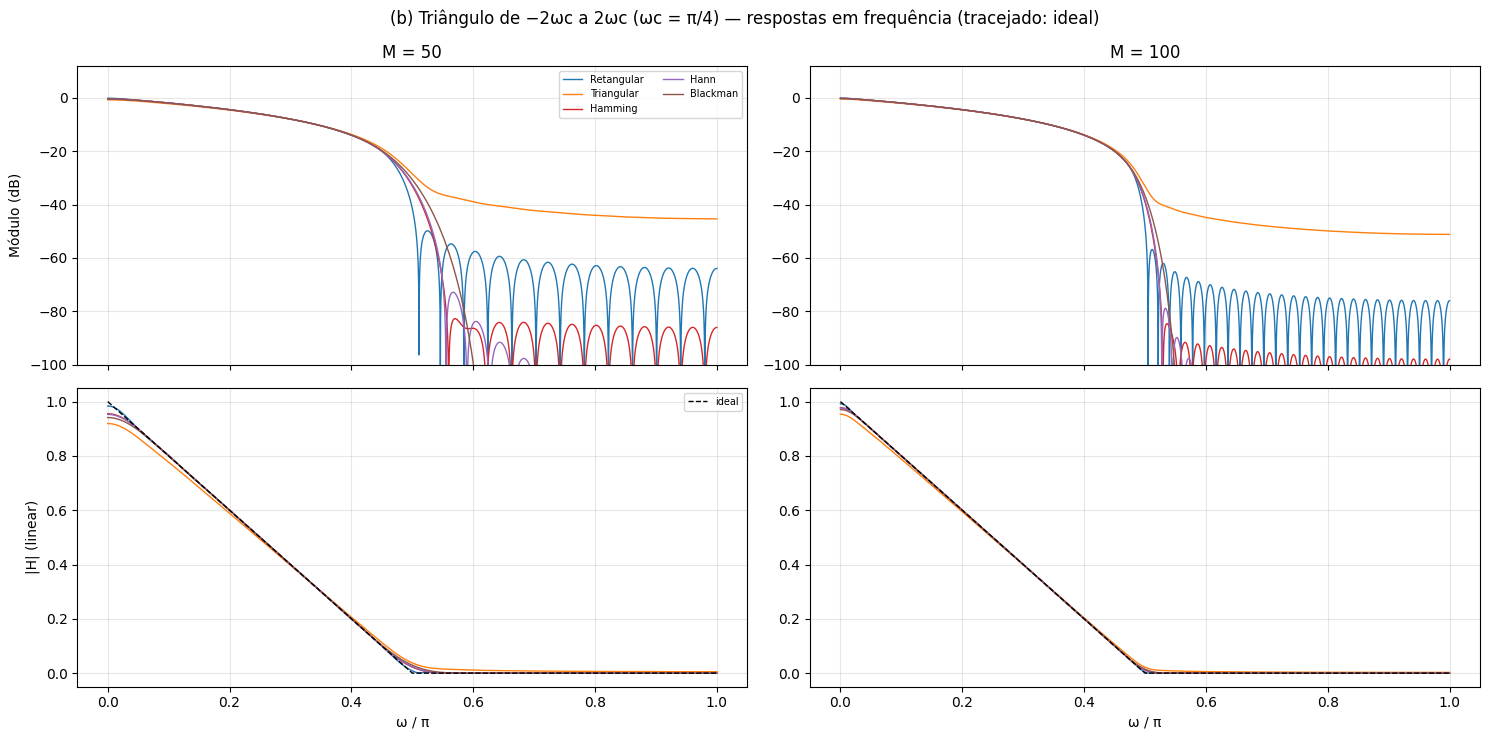

In [ ]:
tabela_erro_q2("b")
figura_impulso_q2("b"); figura_pz_q2("b"); figura_resposta_q2("b")

### (c) Rampa e patamar

=== (c) Rampa até π/4, patamar até π/2 ===
janela      | M=50 : erro RMS   erro máx (fora da guarda) | M=100: erro RMS   erro máx (fora da guarda)
Retangular  |   0.0626     0.0454                  |   0.0451     0.0336                 
Triangular  |   0.0915     0.1301                  |   0.0642     0.0772                 
Hamming     |   0.0829     0.0904                  |   0.0583     0.0452                 
Hann        |   0.0861     0.0943                  |   0.0605     0.0472                 
Blackman    |   0.0950     0.1174                  |   0.0665     0.0587                 


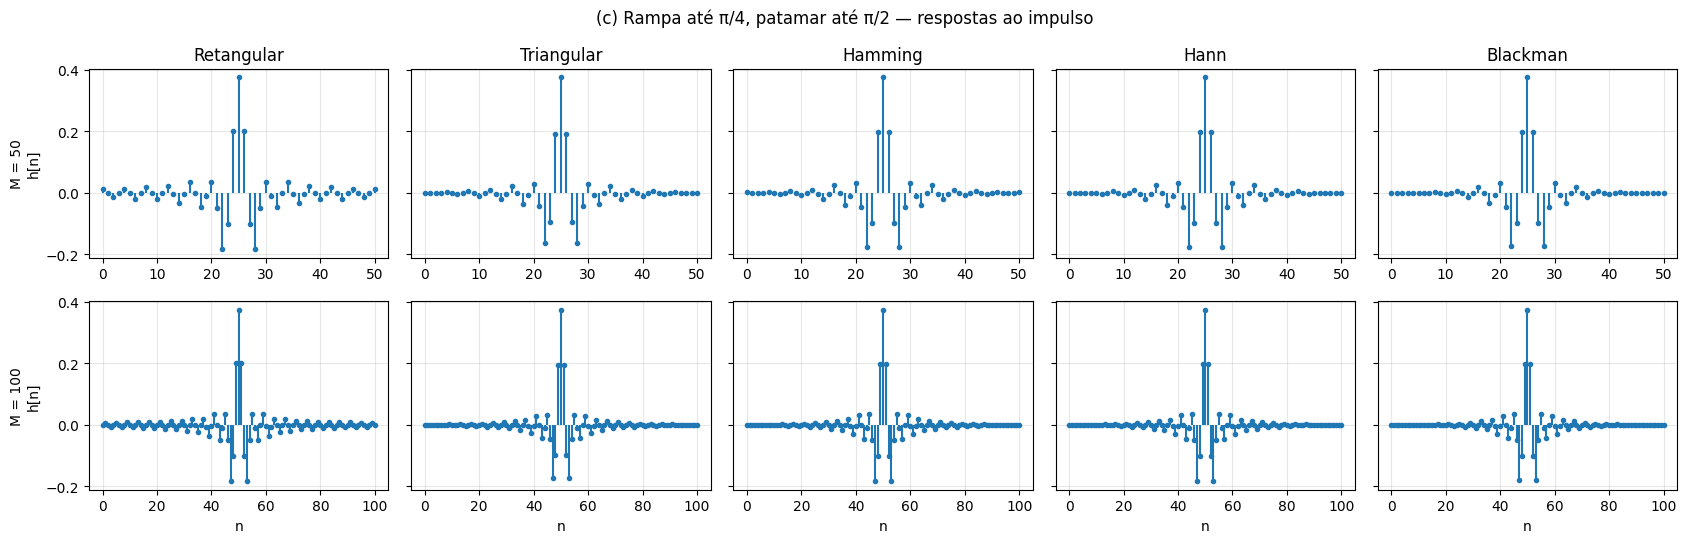

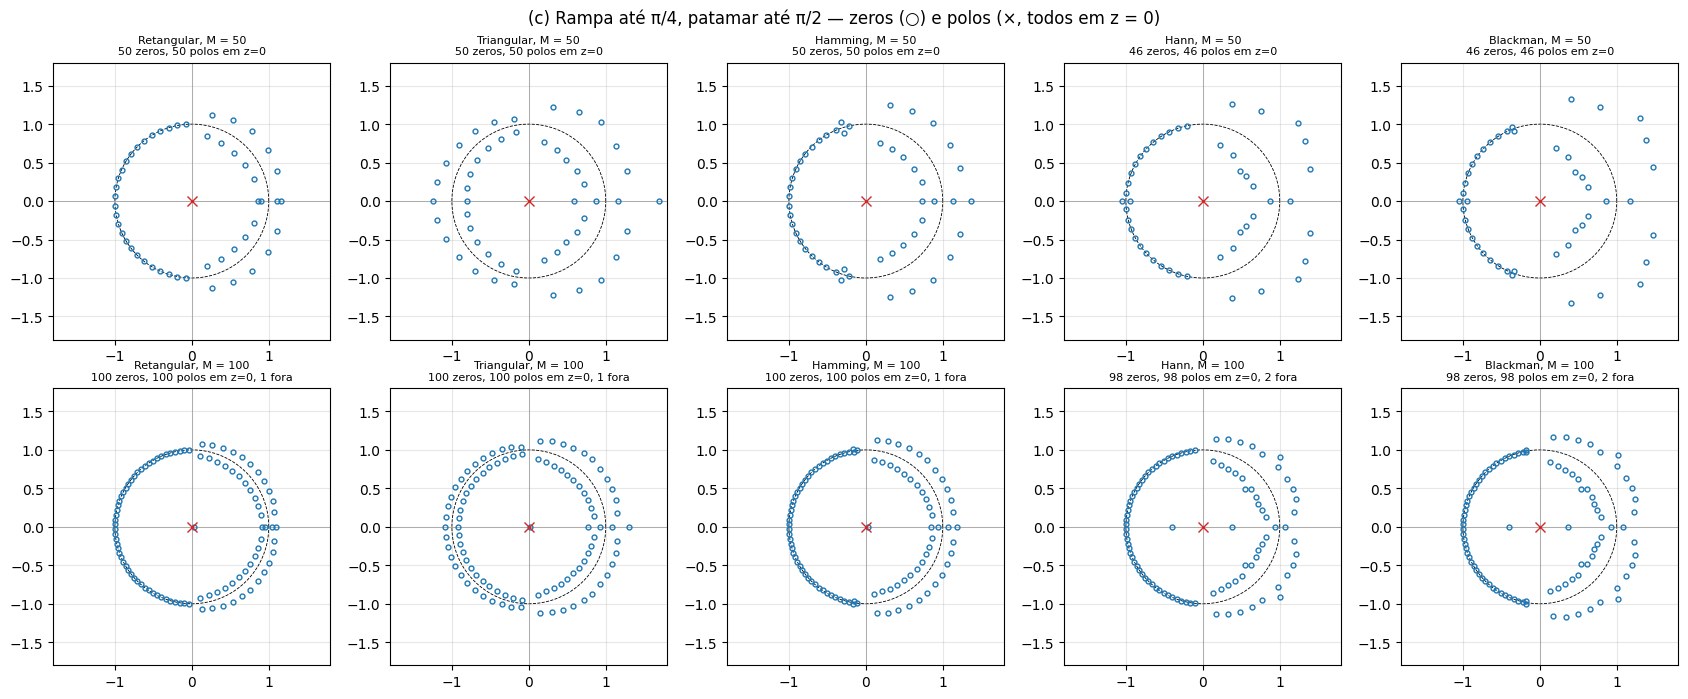

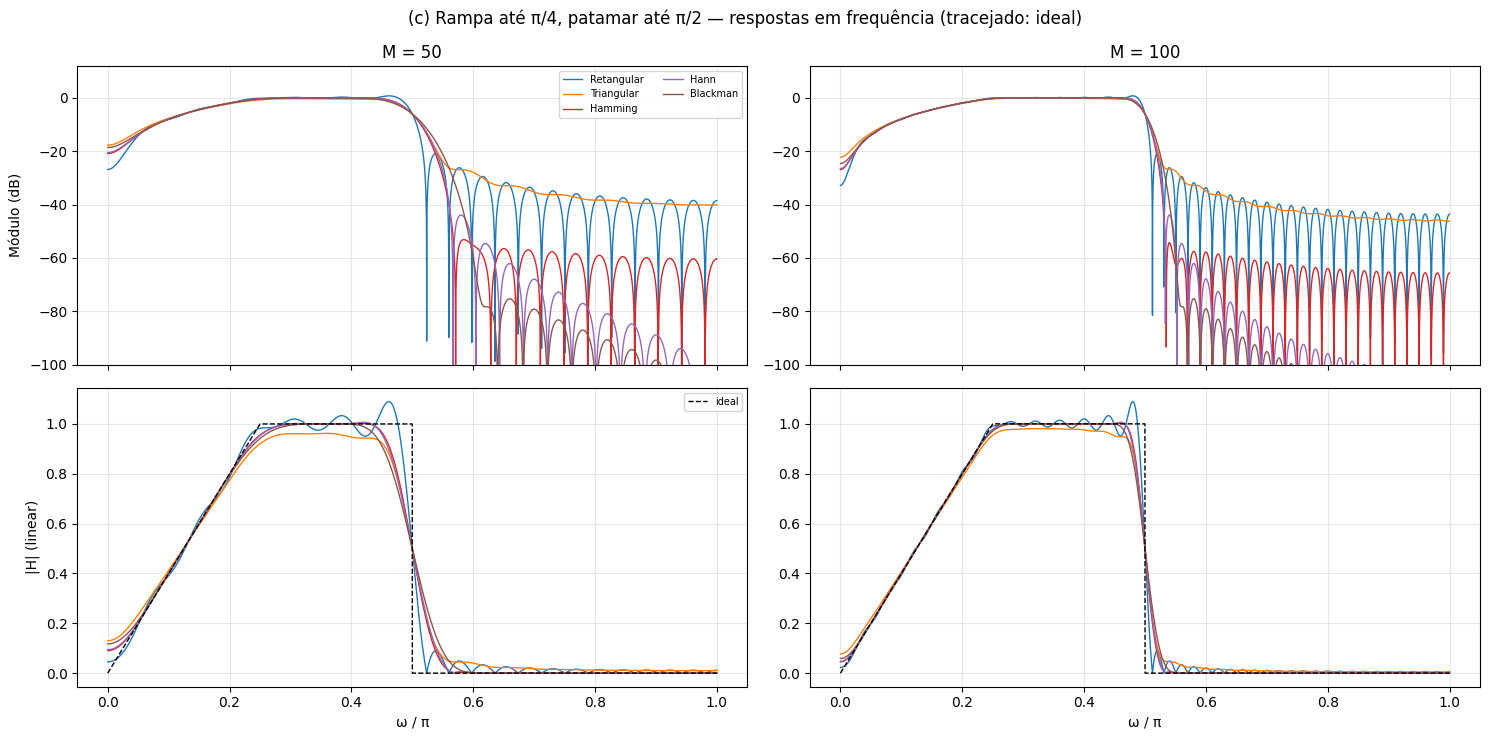

In [ ]:
tabela_erro_q2("c")
figura_impulso_q2("c"); figura_pz_q2("c"); figura_resposta_q2("c")

### Leitura dos resultados (Questão 2)

- **Dois erros, duas leituras.** O **erro RMS** (em toda a faixa) é dominado pela região de transição e cai ≈ $1/\sqrt2$ ao dobrar $M$
  (em (a), retangular: 0,089 → 0,062). Janelas de transição mais larga têm RMS **maior** (em (a) com $M=50$: retangular 0,089 × Blackman 0,132).
  O **erro máx fora da guarda** mede a ondulação longe das descontinuidades: em (a) é ≈ 0,002–0,003 para Hamming/Hann e ≈ 0,0003 para Blackman,
  contra ≈ 0,035–0,07 para retangular e triangular (dezenas a centenas de vezes maior).
- **(a) e (c):** têm descontinuidades (em $\pi/6$, $\pi/3$ e $\pi/2$), então a escolha da janela é determinante: a retangular acompanha melhor os
  degraus, mas ondula; Hamming, Hann e Blackman eliminam a ondulação ao custo de arredondar os degraus. Em (a), com $M=50$ os degraus em $\pi/6$ e $\pi/3$
  (separados por $\pi/6$ rad) ficam arredondados; com $M=100$ o patamar de valor 1 fica mais nítido.
- **(b) (triângulo):** a resposta ideal é **contínua** e $h_d[n]$ decai como $1/n^2$ (nos outros casos, como $1/n$), então a truncagem retangular
  já é muito boa (RMS 0,0017 e erro máx 0,016 com $M=50$). Janelas mais largas só arredondam a quina do triângulo, e por isso o erro **aumenta**
  (erro máx 0,059 com Blackman): aqui a retangular é a melhor.
- Todos os filtros têm fase linear, atraso $M/2$, estabilidade garantida (polos em $z=0$) e zeros em pares conjugados e recíprocos.

## Questão 3 — Remoção de interferências em `handel.wav` com filtros FIR

$y(t)=x(t)+0{,}05\cos(200\pi t)+0{,}075\sin(4000\pi t)+n(t)$: tons em **100 Hz** e **2000 Hz** mais ruído branco de variância
$\sigma^2\in\{10^{-2},10^{-1},1\}$. O ruído usa o **mesmo vetor-base** $N(0,1)$ (semente 0) da prática IIR, de modo que os sinais
contaminados, e portanto as métricas, são diretamente comparáveis.

**Sistema FIR (cascata de três filtros pelo método das janelas):** rejeita-faixas em torno de 100 Hz, rejeita-faixas em torno de 2000 Hz
e passa-baixas em 3500 Hz. Um FIR estreito exige ordem alta: a transição da janela de Hamming vale $\approx 3{,}3f_s/M$ Hz. O filtro completo tem
$M_{tot}=M_1+M_2+M_3$ e atraso de grupo $M_{tot}/2$ amostras, **compensado** na saída (processamento offline).

**Referência IIR (prática anterior):** notch 100 Hz ($r=0{,}995$), notch 2000 Hz ($r=0{,}98$), passa-baixas 3500 Hz ($r=0{,}6$), em cascata.

In [ ]:
fs_a, x = ler_wav("handel.wav")
N = len(x); t = np.arange(N) / fs_a
F0_BAIXA, F0_ALTA = 100.0, 2000.0

interf_baixa = 0.05 * np.cos(200 * np.pi * t)
interf_alta = 0.075 * np.sin(4000 * np.pi * t)
interf = interf_baixa + interf_alta
SIGMA2 = [1e-2, 1e-1, 1.0]
z_base = np.random.default_rng(0).standard_normal(N)
y_ruidoso = {s2: x + interf + np.sqrt(s2) * z_base for s2 in SIGMA2}

P = lambda v: np.mean(v ** 2)
snr = lambda ref, est: 10 * np.log10(P(ref) / P(est - ref))

def calculate_spectrum(signal, sampling_frequency):
    # espectro de amplitude unilateral: 1/N * |FFT|
    n = len(signal)
    yf = np.fft.fft(signal)
    xf = np.fft.fftfreq(n, 1.0 / sampling_frequency)[:n // 2]
    return xf, np.abs(yf[:n // 2]) / n

def amplitude_pico(f, a, f0, tol=3.0):
    return a[np.abs(f - f0) <= tol].max()

print(f"handel.wav: fs = {fs_a} Hz, N = {N} amostras, duração = {N/fs_a:.2f} s, pico = {np.max(np.abs(x)):.3f}")
print(f"Potências: x = {P(x):.5f} | tom de 100 Hz = {P(interf_baixa):.5f} | tom de 2000 Hz = {P(interf_alta):.5f}")
for s2 in SIGMA2:
    print(f"σ² = {s2:<5}: SNR de entrada = {snr(x, y_ruidoso[s2]):6.2f} dB")

handel.wav: fs = 8192 Hz, N = 73113 amostras, duração = 8.92 s, pico = 0.800
Potências: x = 0.03851 | tom de 100 Hz = 0.00125 | tom de 2000 Hz = 0.00281
σ² = 0.01 : SNR de entrada =   4.35 dB
σ² = 0.1  : SNR de entrada =  -4.33 dB
σ² = 1.0  : SNR de entrada = -14.17 dB


### (a) Projeto do sistema FIR

**Escolha dos parâmetros.** Para cada rejeita-faixas, varre-se a largura da banda de rejeição $B$ e a ordem $M$ (janela de Hamming) e medem-se:
a **atenuação** na frequência do tom, $-20\log_{10}|H(f_0)|$, e a **distorção** do sinal, $100\,P(h*x-x)/P(x)$ em %. Procura-se o menor $B$ (menor distorção)
com atenuação suficiente (≥ 40 dB, para que o tom fique abaixo do ruído mais fraco).

In [ ]:
def filtrar_fir_bruto(x_in, h):
    # convolução linear via FFT (implementação própria), saída com N + M amostras
    n = len(x_in) + len(h) - 1
    nfft = 1 << int(np.ceil(np.log2(n)))
    return np.fft.irfft(np.fft.rfft(x_in, nfft) * np.fft.rfft(h, nfft), nfft)[:n]

def filtrar_fir(h, x_in):
    # compensa o atraso de grupo (M/2 amostras): saída alinhada com a entrada (uso offline)
    alfa = (len(h) - 1) // 2
    return filtrar_fir_bruto(x_in, h)[alfa: alfa + len(x_in)]

def H_em(h, f, fs):
    return np.sum(h * np.exp(-1j * 2 * np.pi * f / fs * np.arange(len(h))))

def varredura_notch(f0, larguras, ordens, janela="Hamming"):
    print(f"Rejeita-faixas em {f0:.0f} Hz ({janela}): atenuação em f0 (dB) / distorção (% de Px)")
    print(f"{'B (Hz)':>7} | " + " | ".join(f"M={M:<5d}" .ljust(17) for M in ordens))
    for B in larguras:
        col = []
        for M in ordens:
            h = projetar_fir("bsf", [f0 - B / 2, f0 + B / 2], fs_a, M, janela)
            att = -20 * np.log10(abs(H_em(h, f0, fs_a)) + 1e-15)
            dist = 100 * P(filtrar_fir(h, x) - x) / P(x)
            col.append(f"{att:6.1f} / {dist:6.3f}".ljust(17))
        print(f"{B:7.0f} | " + " | ".join(col))

varredura_notch(100.0, [20, 40, 60, 100], [256, 512, 1024, 2048])
print()
varredura_notch(2000.0, [40, 80, 160, 320], [128, 256, 512, 1024])

Rejeita-faixas em 100 Hz (Hamming): atenuação em f0 (dB) / distorção (% de Px)
 B (Hz) | M=256             | M=512             | M=1024            | M=2048           
     20 |    3.5 /  0.038   |    8.2 /  0.080   |   23.6 /  0.138   |   56.1 /  0.182  
     40 |    8.2 /  0.140   |   23.5 /  0.225   |   56.3 /  0.277   |   52.2 /  0.286  
     60 |   14.6 /  0.278   |   51.5 /  0.362   |   54.3 /  0.375   |   96.3 /  0.377  
    100 |   37.4 /  0.581   |   58.5 /  0.695   |   55.3 /  0.761   |   94.9 /  0.783  

Rejeita-faixas em 2000 Hz (Hamming): atenuação em f0 (dB) / distorção (% de Px)
 B (Hz) | M=128             | M=256             | M=512             | M=1024           
     40 |    3.5 /  0.012   |    8.2 /  0.028   |   23.6 /  0.051   |   55.8 /  0.065  
     80 |    8.2 /  0.043   |   23.6 /  0.078   |   55.3 /  0.097   |   52.1 /  0.103  
    160 |   23.6 /  0.132   |   56.4 /  0.147   |   52.1 /  0.149   |   56.3 /  0.152  
    320 |   54.3 /  0.392   |   52.1 /  0.448   

In [ ]:
# ---------------- Sistema FIR adotado ----------------
JANELA_FIR = "Hamming"
PROJ_FIR = [  # (nome, tipo, [fc...], M)
    ("Rejeita-faixas 100 Hz",  "bsf", [F0_BAIXA - 20.0, F0_BAIXA + 20.0], 1024),
    ("Rejeita-faixas 2000 Hz", "bsf", [F0_ALTA - 40.0, F0_ALTA + 40.0], 512),
    ("Passa-baixas 3500 Hz",   "lpf", [3500.0], 100),
]
nomes_fir = [p[0] for p in PROJ_FIR]
blocos_fir = [projetar_fir(tipo, fcs, fs_a, M, JANELA_FIR) for _, tipo, fcs, M in PROJ_FIR]
h_tot = np.array([1.0])
for h in blocos_fir:
    h_tot = np.convolve(h_tot, h)
M_tot = len(h_tot) - 1
print(f"Janela: {JANELA_FIR}. Ordens: {[p[3] for p in PROJ_FIR]} -> filtro completo de ordem {M_tot} ({M_tot + 1} coeficientes)")
print(f"Atraso de grupo = {M_tot/2:.0f} amostras = {1000*(M_tot/2)/fs_a:.1f} ms (compensado na saída)")
for (nome, tipo, fcs, M), h in zip(PROJ_FIR, blocos_fir):
    print(f"{nome}: fc = {fcs} Hz, M = {M}; |H(100 Hz)| = {20*np.log10(abs(H_em(h, 100.0, fs_a))+1e-15):7.1f} dB,"
          f" |H(2000 Hz)| = {20*np.log10(abs(H_em(h, 2000.0, fs_a))+1e-15):7.1f} dB")
print(f"Filtro completo: |H(100 Hz)| = {20*np.log10(abs(H_em(h_tot, 100.0, fs_a))+1e-15):.1f} dB, "
      f"|H(2000 Hz)| = {20*np.log10(abs(H_em(h_tot, 2000.0, fs_a))+1e-15):.1f} dB, "
      f"|H(0)| = {20*np.log10(abs(H_em(h_tot, 0.0, fs_a))):.3f} dB")

Janela: Hamming. Ordens: [1024, 512, 100] -> filtro completo de ordem 1636 (1637 coeficientes)
Atraso de grupo = 818 amostras = 99.9 ms (compensado na saída)
Rejeita-faixas 100 Hz: fc = [80.0, 120.0] Hz, M = 1024; |H(100 Hz)| =   -56.3 dB, |H(2000 Hz)| =     0.0 dB
Rejeita-faixas 2000 Hz: fc = [1960.0, 2040.0] Hz, M = 512; |H(100 Hz)| =     0.0 dB, |H(2000 Hz)| =   -55.3 dB
Passa-baixas 3500 Hz: fc = [3500.0] Hz, M = 100; |H(100 Hz)| =    -0.0 dB, |H(2000 Hz)| =    -0.0 dB
Filtro completo: |H(100 Hz)| = -56.3 dB, |H(2000 Hz)| = -55.3 dB, |H(0)| = -0.017 dB


In [ ]:
# ---------------- Sistema IIR da prática anterior (para comparação) ----------------
def projetar_bloco_iir(tipo, fc, r, fs):
    wc = 2 * np.pi * fc / fs
    m1, m2 = -2 * r * np.cos(wc), r ** 2
    a = np.array([1.0, m1, m2])
    if tipo == "lpf":
        b = np.array([1.0, 2.0, 1.0]);  ganho = (1 + m1 + m2) / 4
    elif tipo == "notch":
        b = np.array([1.0, -2 * np.cos(wc), 1.0]); ganho = (1 + m1 + m2) / (2 - 2 * np.cos(wc))
    return ganho * b, a

blocos_iir = [projetar_bloco_iir("notch", F0_BAIXA, 0.995, fs_a), projetar_bloco_iir("notch", F0_ALTA, 0.98, fs_a),
              projetar_bloco_iir("lpf", 3500.0, 0.6, fs_a)]
sos_iir = np.array([np.r_[b, a] for b, a in blocos_iir])

def resposta_iir(b, a, f, fs):
    # H(e^{jw}) = B(e^{-jw}) / A(e^{-jw}), avaliada diretamente
    z1 = np.exp(-1j * 2 * np.pi * np.asarray(f) / fs)
    return np.polyval(b[::-1], z1) / np.polyval(a[::-1], z1)

def resposta_iir_cascata(f):
    H = np.ones(len(f), complex)
    for b, a in blocos_iir:
        H = H * resposta_iir(b, a, f, fs_a)
    return H

filtro_fir = lambda v: filtrar_fir(h_tot, v)
filtro_iir = lambda v: sosfilt(sos_iir, v)
filtro_iir_fz = lambda v: sosfiltfilt(sos_iir, v)
print("Sistema IIR reconstruído: 3 blocos de 2ª ordem (ordem total 6).")

Sistema IIR reconstruído: 3 blocos de 2ª ordem (ordem total 6).


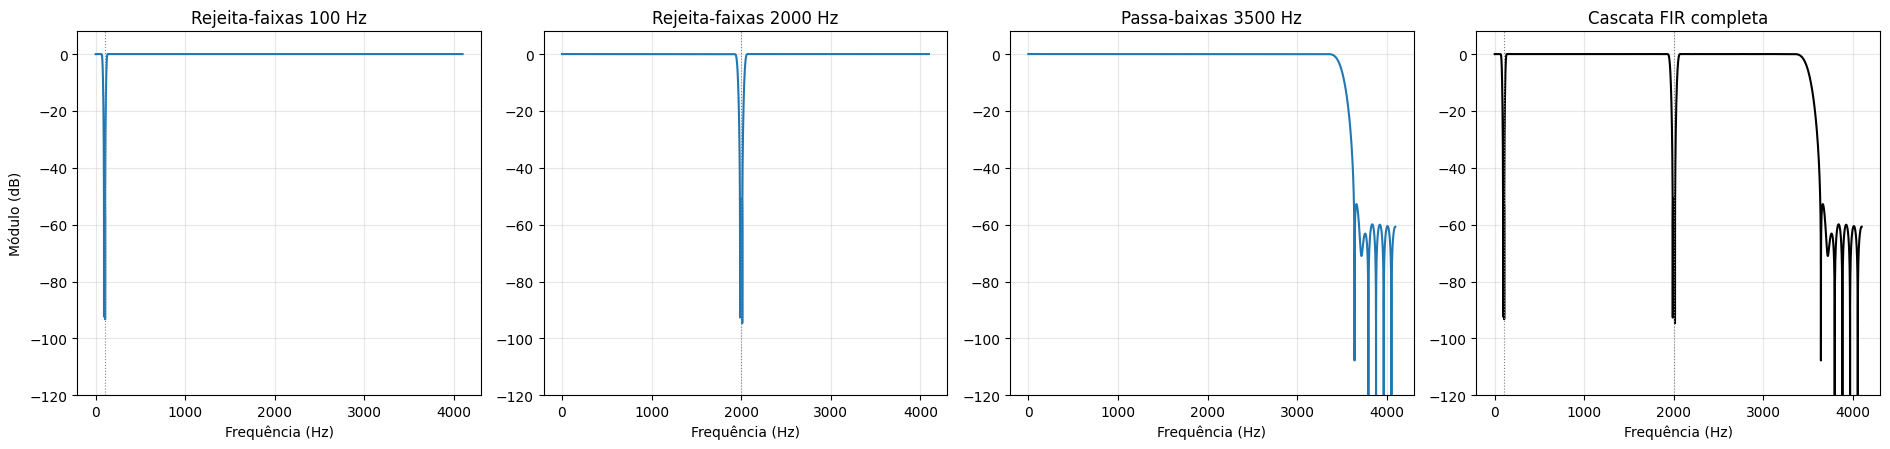

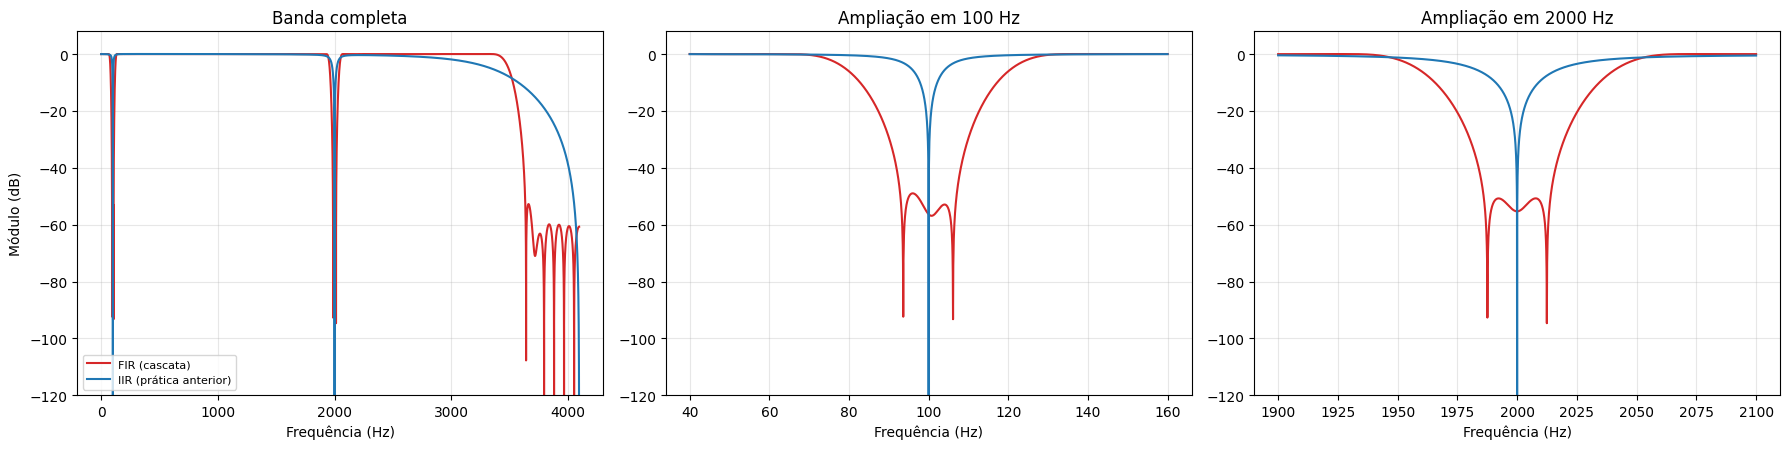

FIR: atraso de grupo constante = 818.0 amostras (esperado M_tot/2 = 818)
IIR: atraso de grupo varia: 0.35 a 1.32 amostras entre 200 e 1800 Hz


In [ ]:
# ---------------- Resposta em frequência: cada bloco FIR, o conjunto e a comparação com o IIR ----------------
F_A = np.linspace(0, fs_a / 2, 16384)
fig, eixos = plt.subplots(1, 4, figsize=(19, 4.6))
for j, (h, nome) in enumerate(zip(blocos_fir + [h_tot], nomes_fir + ["Cascata FIR completa"])):
    f_, H_ = resposta_frequencia(h, fs_a, 1 << 17)
    eixos[j].plot(f_, em_db(H_), color="tab:blue" if j < 3 else "k")
    eixos[j].set_title(nome); eixos[j].set_ylim(-120, 8); eixos[j].grid(True, alpha=0.3); eixos[j].set_xlabel("Frequência (Hz)")
    for f0 in ([F0_BAIXA] if j == 0 else [F0_ALTA] if j == 1 else [F0_BAIXA, F0_ALTA] if j == 3 else []):
        eixos[j].axvline(f0, color="gray", ls=":", lw=0.8)
eixos[0].set_ylabel("Módulo (dB)")
plt.tight_layout(); plt.show()

# Comparação FIR x IIR (módulo; ampliações em torno dos dois tons)
f_f, H_f = resposta_frequencia(h_tot, fs_a, 1 << 17)
H_i = resposta_iir_cascata(f_f)
fig, eixos = plt.subplots(1, 3, figsize=(18, 4.6))
for ax, (lo, hi, tit) in zip(eixos, [(0, fs_a / 2, "Banda completa"), (40, 160, "Ampliação em 100 Hz"), (1900, 2100, "Ampliação em 2000 Hz")]):
    sel = (f_f >= lo) & (f_f <= hi)
    ax.plot(f_f[sel], em_db(H_f[sel]), color="tab:red", label="FIR (cascata)")
    ax.plot(f_f[sel], em_db(H_i[sel]), color="tab:blue", label="IIR (prática anterior)")
    ax.set_title(tit); ax.set_xlabel("Frequência (Hz)"); ax.set_ylim(-120, 8); ax.grid(True, alpha=0.3)
eixos[0].set_ylabel("Módulo (dB)"); eixos[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

# Fase / atraso
fase_f = np.unwrap(np.angle(H_f)); fase_i = np.unwrap(np.angle(H_i))
sel = (f_f > 200) & (f_f < 1800)
atraso_fir = -np.polyfit(2 * np.pi * f_f[sel] / fs_a, fase_f[sel], 1)[0]
print(f"FIR: atraso de grupo constante = {atraso_fir:.1f} amostras (esperado M_tot/2 = {M_tot/2:.0f})")
atraso_iir = -np.gradient(fase_i, 2 * np.pi * f_f / fs_a)
print(f"IIR: atraso de grupo varia: {np.min(atraso_iir[sel]):.2f} a {np.max(atraso_iir[sel]):.2f} amostras entre 200 e 1800 Hz")

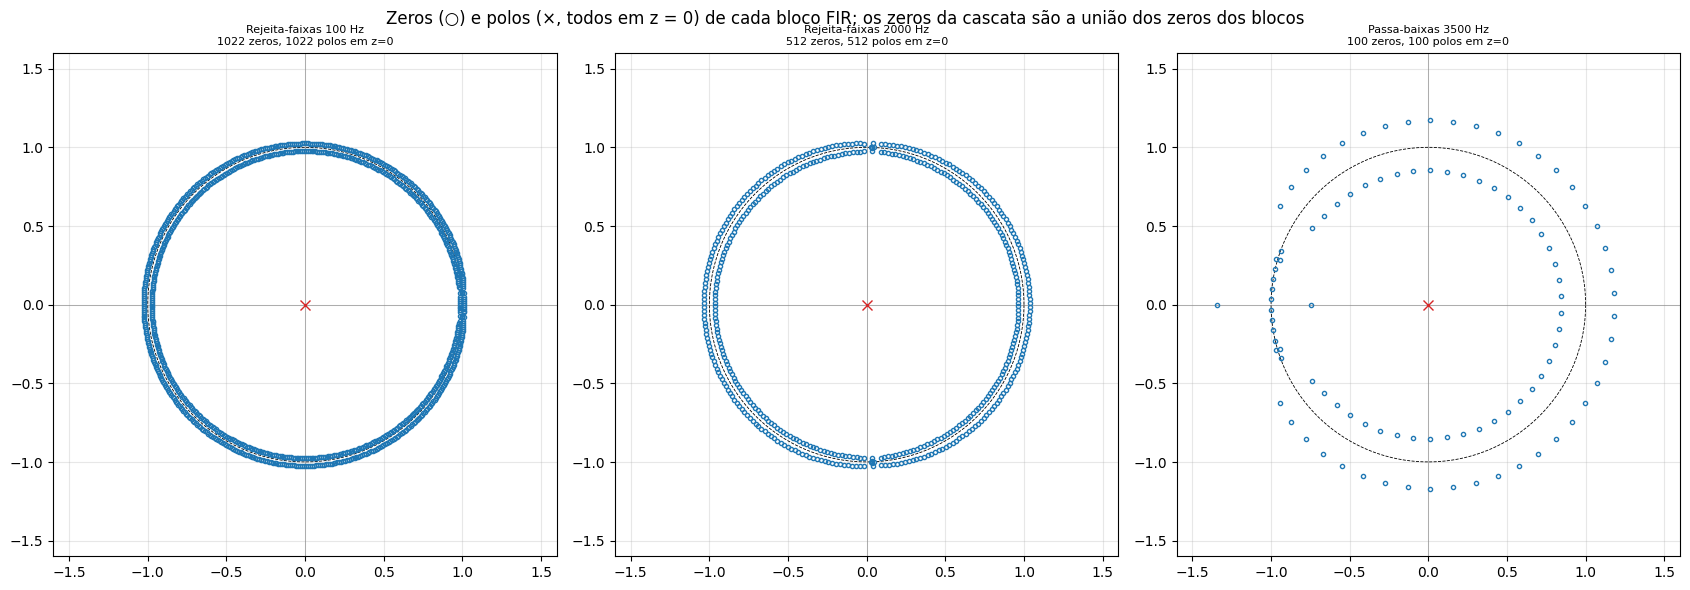

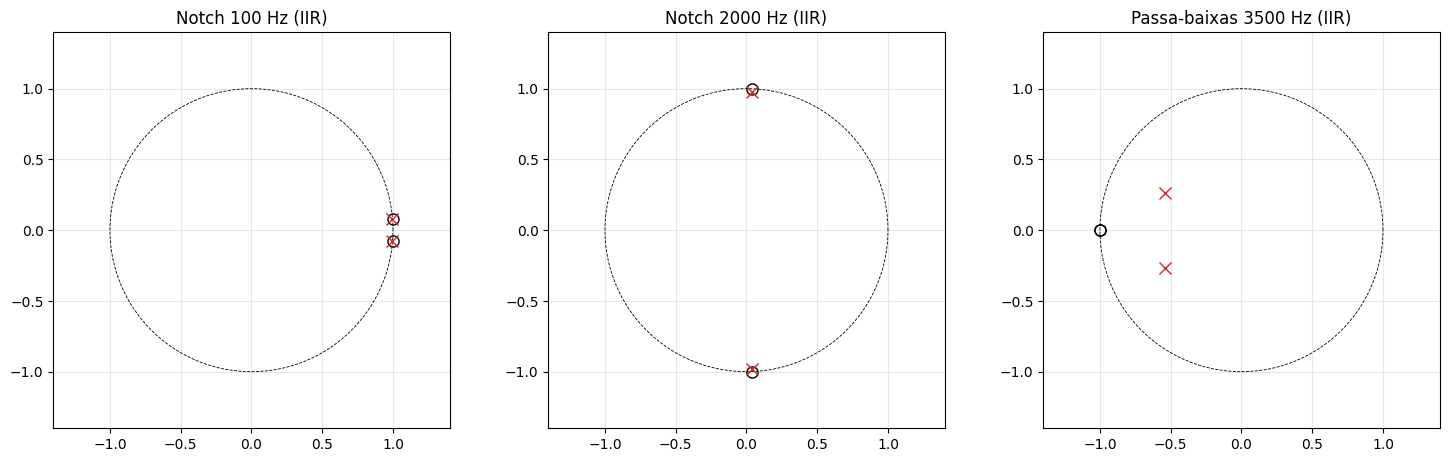

In [ ]:
# ---------------- Diagramas de polos e zeros dos blocos FIR ----------------
fig, eixos = plt.subplots(1, 3, figsize=(17, 5.8))
for ax, h, nome in zip(eixos, blocos_fir, nomes_fir):
    desenhar_pz(ax, h, nome, lim=1.6, ms=3)
fig.suptitle("Zeros (○) e polos (×, todos em z = 0) de cada bloco FIR; os zeros da cascata são a união dos zeros dos blocos")
plt.tight_layout(); plt.show()

# Referência: zeros e polos dos blocos IIR (prática anterior)
fig, eixos = plt.subplots(1, 3, figsize=(15, 4.6))
theta = np.linspace(0, 2 * np.pi, 400)
for ax, (b, a), nome in zip(eixos, blocos_iir, ["Notch 100 Hz (IIR)", "Notch 2000 Hz (IIR)", "Passa-baixas 3500 Hz (IIR)"]):
    z, p = np.roots(b), np.roots(a)
    ax.plot(np.cos(theta), np.sin(theta), "k--", lw=0.6)
    ax.plot(z.real, z.imag, "o", mfc="none", mec="k", ms=8); ax.plot(p.real, p.imag, "x", color="tab:red", ms=8)
    ax.set_title(nome); ax.set_aspect("equal"); ax.set_xlim(-1.4, 1.4); ax.set_ylim(-1.4, 1.4); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

### (b) Filtragem: comparação entre $x$, $y$ e $\hat x$ (FIR e IIR)

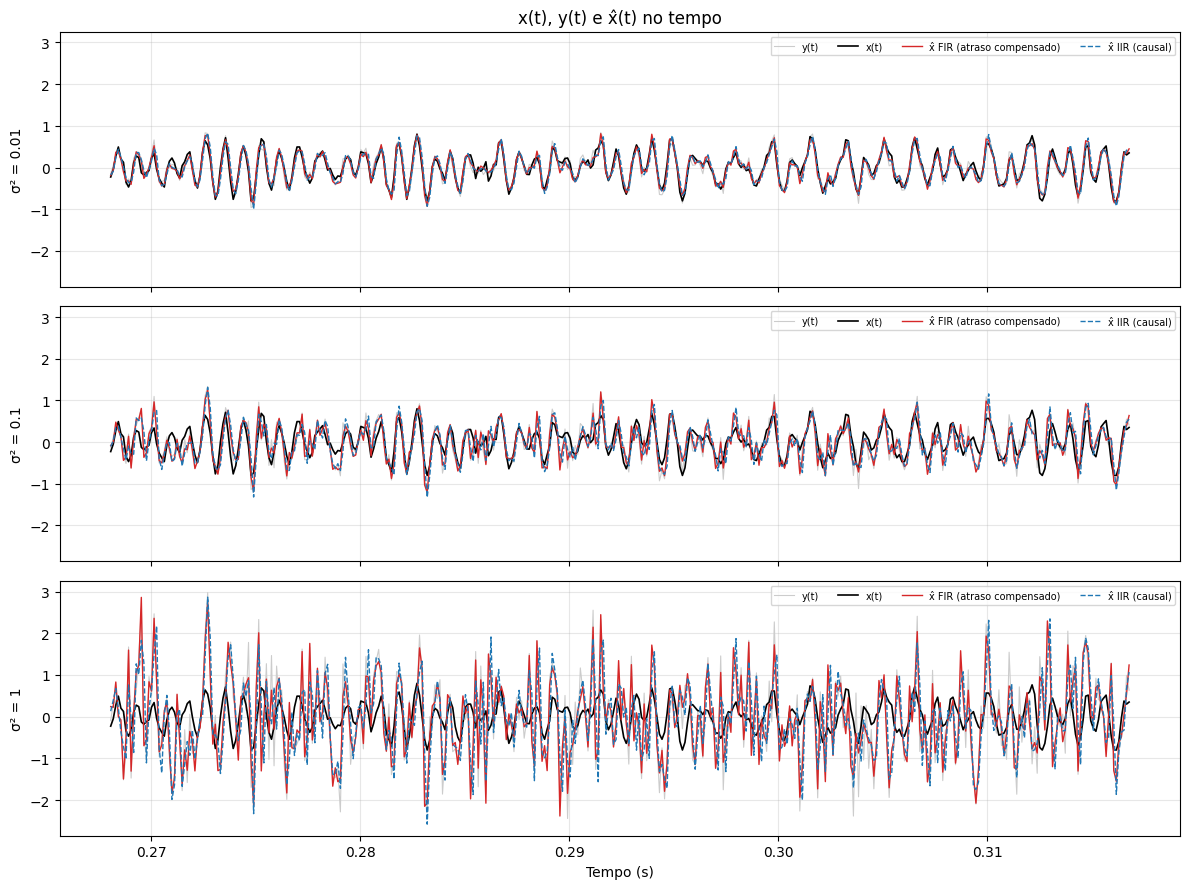

In [ ]:
x_hat_fir = {s2: filtro_fir(y_ruidoso[s2]) for s2 in SIGMA2}
x_hat_iir = {s2: filtro_iir(y_ruidoso[s2]) for s2 in SIGMA2}

energia_local = np.convolve(x ** 2, np.ones(400) / 400, mode="same")
i0 = int(np.argmax(energia_local)); janela = slice(i0 - 200, i0 + 200)

fig, eixos = plt.subplots(3, 1, figsize=(12, 9), sharex=True, sharey=True)
for ax, s2 in zip(eixos, SIGMA2):
    ax.plot(t[janela], y_ruidoso[s2][janela], color="0.8", lw=0.8, label="y(t)")
    ax.plot(t[janela], x[janela], color="k", lw=1.2, label="x(t)")
    ax.plot(t[janela], x_hat_fir[s2][janela], color="tab:red", lw=1.0, label="x̂ FIR (atraso compensado)")
    ax.plot(t[janela], x_hat_iir[s2][janela], color="tab:blue", lw=1.0, ls="--", label="x̂ IIR (causal)")
    ax.set_ylabel(f"σ² = {s2:g}"); ax.grid(True, alpha=0.3); ax.legend(fontsize=7, loc="upper right", ncol=4)
eixos[0].set_title("x(t), y(t) e x̂(t) no tempo")
eixos[-1].set_xlabel("Tempo (s)")
plt.tight_layout(); plt.show()

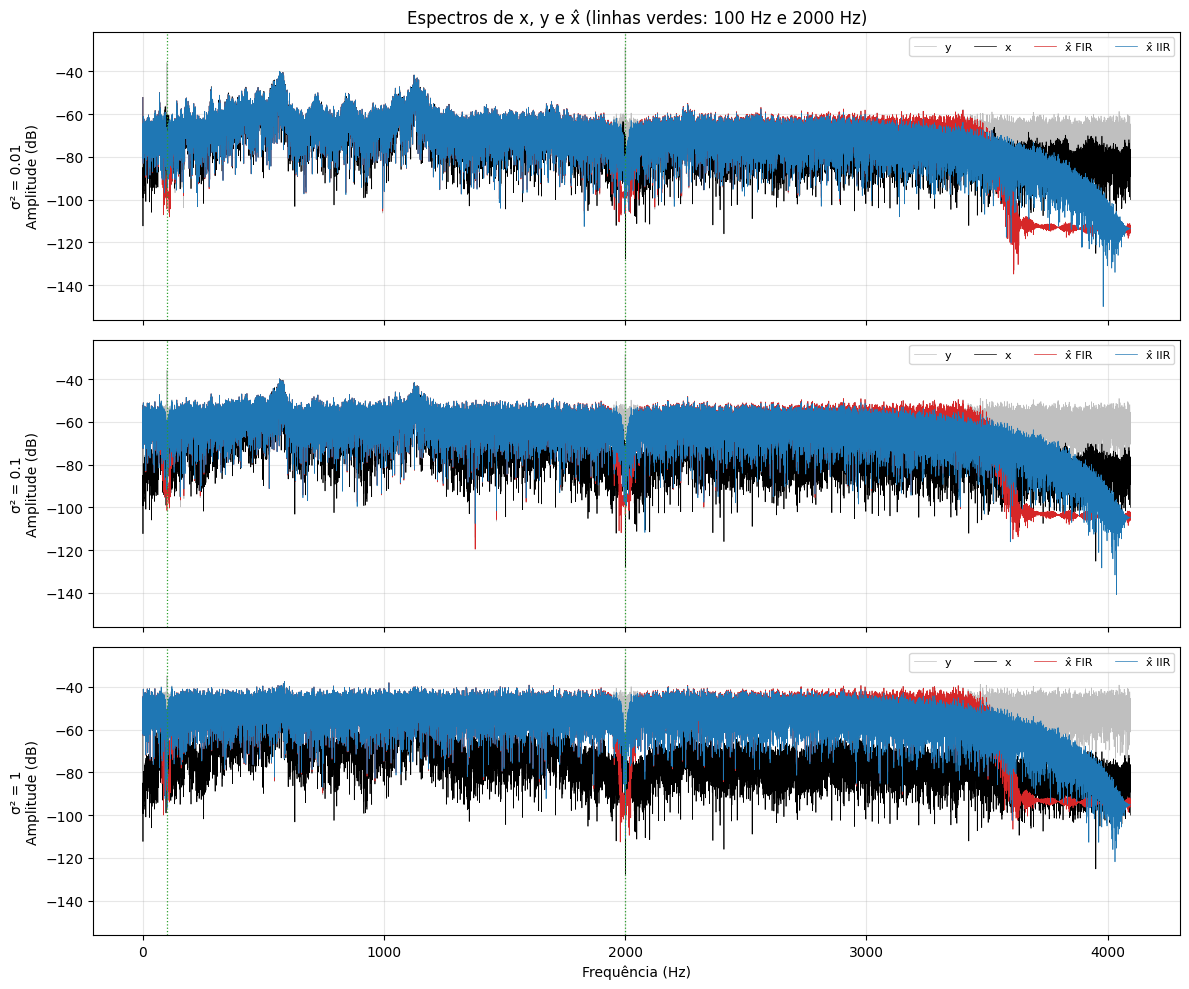

    σ² |  tom 100 Hz: y       FIR       IIR |  tom 2000 Hz: y       FIR       IIR
  0.01 |        0.01625   0.00004   0.00037 |         0.03667   0.00005   0.00011
   0.1 |        0.01627   0.00005   0.00086 |         0.03786   0.00005   0.00028
     1 |        0.01816   0.00008   0.00275 |         0.04162   0.00005   0.00081


In [ ]:
f_x, a_x = calculate_spectrum(x, fs_a)
fig, eixos = plt.subplots(3, 1, figsize=(12, 10), sharex=True, sharey=True)
for ax, s2 in zip(eixos, SIGMA2):
    f_y, a_y = calculate_spectrum(y_ruidoso[s2], fs_a)
    f_h, a_h = calculate_spectrum(x_hat_fir[s2], fs_a)
    f_i, a_i = calculate_spectrum(x_hat_iir[s2], fs_a)
    ax.plot(f_y, 20 * np.log10(a_y + 1e-12), color="0.75", lw=0.5, label="y")
    ax.plot(f_x, 20 * np.log10(a_x + 1e-12), color="k", lw=0.5, label="x")
    ax.plot(f_h, 20 * np.log10(a_h + 1e-12), color="tab:red", lw=0.5, label="x̂ FIR")
    ax.plot(f_i, 20 * np.log10(a_i + 1e-12), color="tab:blue", lw=0.5, label="x̂ IIR")
    for f0 in (F0_BAIXA, F0_ALTA):
        ax.axvline(f0, color="tab:green", ls=":", lw=0.9)
    ax.set_ylabel(f"σ² = {s2:g}\nAmplitude (dB)"); ax.grid(True, alpha=0.3); ax.legend(fontsize=8, loc="upper right", ncol=4)
eixos[0].set_title("Espectros de x, y e x̂ (linhas verdes: 100 Hz e 2000 Hz)")
eixos[-1].set_xlabel("Frequência (Hz)")
plt.tight_layout(); plt.show()

# Amplitude dos tons antes e depois da filtragem
print(f"{'σ²':>6} | {'tom 100 Hz: y':>14} {'FIR':>9} {'IIR':>9} | {'tom 2000 Hz: y':>15} {'FIR':>9} {'IIR':>9}")
for s2 in SIGMA2:
    f_y, a_y = calculate_spectrum(y_ruidoso[s2], fs_a)
    f_h, a_h = calculate_spectrum(x_hat_fir[s2], fs_a); f_i, a_i = calculate_spectrum(x_hat_iir[s2], fs_a)
    print(f"{s2:6g} | {amplitude_pico(f_y, a_y, 100):14.5f} {amplitude_pico(f_h, a_h, 100):9.5f} {amplitude_pico(f_i, a_i, 100):9.5f} | "
          f"{amplitude_pico(f_y, a_y, 2000):15.5f} {amplitude_pico(f_h, a_h, 2000):9.5f} {amplitude_pico(f_i, a_i, 2000):9.5f}")

### (c) Desempenho quantitativo (FIR × IIR)

P_x = 0.03851.  'P resíduo' = potência de (interferências + ruído) após o filtro; 'P dist.' = potência de (H{x} - x).
    σ² sistema              |  SNR in  SNR out   ΔSNR |   MSE in  MSE out |  P resíduo   P dist. dist (% Px)
  0.01 FIR (atraso comp.)   |    4.35     6.62   2.27 |   0.0141   0.0084 |     0.0081   0.00026        0.68
  0.01 IIR causal           |    4.35     5.91   1.56 |   0.0141   0.0099 |     0.0073   0.00258        6.71
  0.01 IIR fase zero        |    4.35     7.48   3.13 |   0.0141   0.0069 |     0.0065   0.00034        0.88
   0.1 FIR (atraso comp.)   |   -4.33    -3.26   1.07 |   0.1043   0.0815 |     0.0813   0.00026        0.68
   0.1 IIR causal           |   -4.33    -2.91   1.42 |   0.1043   0.0752 |     0.0725   0.00258        6.71
   0.1 IIR fase zero        |   -4.33    -2.32   2.01 |   0.1043   0.0657 |     0.0653   0.00034        0.88
     1 FIR (atraso comp.)   |  -14.17   -13.24   0.92 |   1.0052   0.8129 |     0.8126   0.00026        0.68
     1 IIR

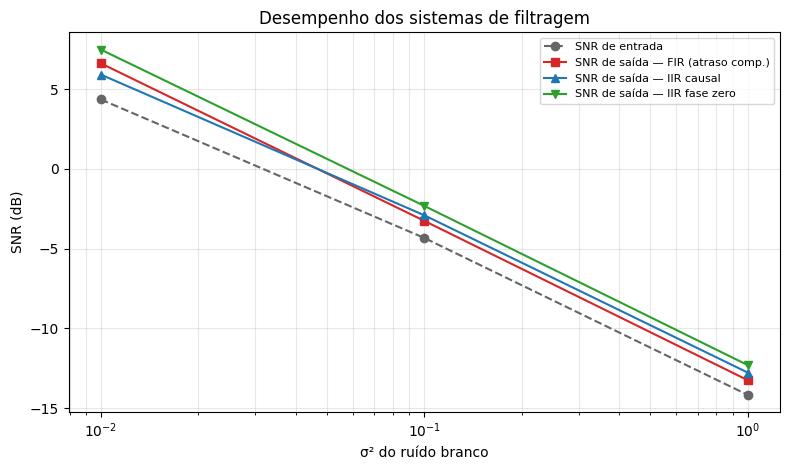

In [ ]:
def metricas_filtragem(filtrar, x_ref, y, e):
    xh, xf, ef = filtrar(y), filtrar(x_ref), filtrar(e)
    return dict(snr_in=snr(x_ref, y), snr_out=snr(x_ref, xh), mse_in=P(y - x_ref), mse_out=P(xh - x_ref),
                p_res=P(ef), p_dist=P(xf - x_ref), xh=xh)

SISTEMAS = {"FIR (atraso comp.)": filtro_fir, "IIR causal": filtro_iir, "IIR fase zero": filtro_iir_fz}
resultados_c = {nome: {} for nome in SISTEMAS}
print(f"P_x = {P(x):.5f}.  'P resíduo' = potência de (interferências + ruído) após o filtro; 'P dist.' = potência de (H{{x}} - x).")
print(f"{'σ²':>6} {'sistema':<20} | {'SNR in':>7} {'SNR out':>8} {'ΔSNR':>6} | {'MSE in':>8} {'MSE out':>8} | {'P resíduo':>10} {'P dist.':>9} {'dist (% Px)':>11}")
for s2 in SIGMA2:
    y_ = y_ruidoso[s2]; e_ = y_ - x
    for nome, filtrar in SISTEMAS.items():
        m = metricas_filtragem(filtrar, x, y_, e_)
        resultados_c[nome][s2] = m
        print(f"{s2:6g} {nome:<20} | {m['snr_in']:7.2f} {m['snr_out']:8.2f} {m['snr_out']-m['snr_in']:6.2f} | {m['mse_in']:8.4f} {m['mse_out']:8.4f} | "
              f"{m['p_res']:10.4f} {m['p_dist']:9.5f} {100*m['p_dist']/P(x):11.2f}")

plt.figure(figsize=(8, 4.8))
plt.semilogx(SIGMA2, [resultados_c["FIR (atraso comp.)"][s]["snr_in"] for s in SIGMA2], "o--", color="0.4", label="SNR de entrada")
for nome, est, cor in [("FIR (atraso comp.)", "s-", "tab:red"), ("IIR causal", "^-", "tab:blue"), ("IIR fase zero", "v-", "tab:green")]:
    plt.semilogx(SIGMA2, [resultados_c[nome][s]["snr_out"] for s in SIGMA2], est, color=cor, label=f"SNR de saída — {nome}")
plt.xlabel("σ² do ruído branco"); plt.ylabel("SNR (dB)"); plt.title("Desempenho dos sistemas de filtragem")
plt.grid(True, which="both", alpha=0.3); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Como ler a tabela.** O ruído branco ocupa toda a banda $[0,f_s/2]$, e a maior parte da potência do sinal $x$ está abaixo de ≈ 3 kHz. O ganho de SNR de um passa-baixas
em $f_m$ é limitado a $10\log_{10}\big((f_s/2)/f_m\big)$ (≈ 0,68 dB para $f_m=3500$ Hz). A potência dos tons ($\approx 0{,}004$) só é dominante para $\sigma^2$ pequeno; por isso a remoção
dos tons melhora bastante a SNR com $\sigma^2=10^{-2}$ e quase nada com $\sigma^2=1$. A **potência de distorção** depende só de $x$ e do filtro, não de $\sigma^2$.
O FIR com atraso compensado e o IIR de fase zero são comparáveis entre si; o IIR causal inclui a distorção de fase no erro.

### (d) Avaliação subjetiva (audição)

In [ ]:
print("Original:"); tocar(x, fs_a)
for s2 in SIGMA2:
    print(f"σ² = {s2:g} — contaminado:"); tocar(y_ruidoso[s2], fs_a)
    print(f"σ² = {s2:g} — recuperado (FIR):"); tocar(x_hat_fir[s2], fs_a)
    print(f"σ² = {s2:g} — recuperado (IIR):"); tocar(x_hat_iir[s2], fs_a)

Original:


σ² = 0.01 — contaminado:


σ² = 0.01 — recuperado (FIR):


σ² = 0.01 — recuperado (IIR):


σ² = 0.1 — contaminado:


σ² = 0.1 — recuperado (FIR):


σ² = 0.1 — recuperado (IIR):


σ² = 1 — contaminado:


σ² = 1 — recuperado (FIR):


σ² = 1 — recuperado (IIR):


**Roteiro para a avaliação subjetiva** (preencher após ouvir os áudios acima):

| Critério | σ² = 0,01 | σ² = 0,1 | σ² = 1 |
|---|---|---|---|
| Inteligibilidade da melodia (FIR) | | | |
| Zumbido de 100 Hz e apito de 2000 Hz ainda audíveis? | | | |
| Chiado residual (potência do ruído) | | | |
| Distorção / som “abafado” (corte do passa-baixas) | | | |
| Pré-eco ou ressoância nas transições (FIR: simétrico; IIR: ressoa depois) | | | |
| Diferença FIR × IIR | | | |

### (e) Quantização dos coeficientes, $b\in\{2,4,8,16\}$ bits

**Quantizador.** Ponto fixo com sinal e $b$ bits, aplicado a cada vetor de coeficientes: $\Delta=2^{e-(b-1)}$, com $e=\lfloor\log_2\max|v|\rfloor+1$ e
$v_q=\Delta\cdot\mathrm{clip}\big(\mathrm{round}(v/\Delta),-2^{b-1},2^{b-1}-1\big)$ (o mesmo da prática IIR).

**Duas estruturas FIR.** (1) *Forma direta*: quantiza-se a resposta ao impulso $h_{tot}$ do filtro completo; (2) *blocos*: quantiza-se cada filtro
(rejeita-faixas 100 Hz, rejeita-faixas 2000 Hz, passa-baixas) e compõe-se a cascata. Um FIR é **sempre estável** (todos os polos em $z=0$);
a quantização altera os **zeros**, o ganho e a atenuação da banda de rejeição. Como o arredondamento é determinístico, a simetria
$h[n]=h[M-n]$ é preservada e a fase continua linear. Para comparação, a mesma quantização é aplicada à cascata IIR da prática anterior.

In [ ]:
def quantizar(v, bits):
    v = np.asarray(v, float)
    vmax = np.max(np.abs(v))
    if vmax == 0:
        return v.copy()
    e = np.floor(np.log2(vmax)) + 1                    # alcance [-2^e, 2^e)
    passo = 2.0 ** (e - (bits - 1))
    return np.clip(np.round(v / passo), -2 ** (bits - 1), 2 ** (bits - 1) - 1) * passo

def cascata_h(hs):
    h = np.array([1.0])
    for hh in hs:
        h = np.convolve(h, hh)
    return h

def quantizar_ba(b, a, bits):
    return quantizar(b, bits), np.r_[1.0, quantizar(a[1:], bits)]

BITS_E = [2, 4, 8, 16]
BITS_VARRE = [2, 4, 6, 8, 10, 12, 14, 16, 20, 24]
y01 = y_ruidoso[0.1]; Hb = lambda h, n=1 << 17: resposta_frequencia(h, fs_a, n)

def avaliar_fir(h_q, y, x_ref):
    # h_q: resposta ao impulso do filtro completo (cascata já composta)
    f_, H_q = Hb(h_q)
    _, H_0 = Hb(h_tot)
    erro_dB = 20 * np.log10(np.max(np.abs(H_q - H_0)) / np.max(np.abs(H_0)) + 1e-15)
    att100 = -20 * np.log10(abs(H_em(h_q, 100.0, fs_a)) + 1e-15)
    att2k = -20 * np.log10(abs(H_em(h_q, 2000.0, fs_a)) + 1e-15)
    saida = filtrar_fir(h_q, y)
    sim = np.max(np.abs(h_q - h_q[::-1]))
    return dict(H=H_q, erro_dB=erro_dB, att100=att100, att2k=att2k, snr=snr(x_ref, saida), simetria=sim, saida=saida)

res_fir = {"blocos": {}, "direta": {}}
for bits in BITS_VARRE:
    hq_blocos = cascata_h([quantizar(h, bits) for h in blocos_fir])
    hq_direta = quantizar(h_tot, bits)
    res_fir["blocos"][bits] = avaliar_fir(hq_blocos, y01, x)
    res_fir["direta"][bits] = avaliar_fir(hq_direta, y01, x)
    res_fir["blocos"][bits]["h"], res_fir["direta"][bits]["h"] = hq_blocos, hq_direta

# Referência IIR (cascata quantizada bloco a bloco, como na prática anterior)
def snr_iir_quantizado(bits, y, x_ref):
    sos_q = np.array([np.r_[quantizar_ba(b, a, bits)[0], quantizar_ba(b, a, bits)[1]] for b, a in blocos_iir])
    polos_max = max(np.max(np.abs(np.roots(quantizar_ba(b, a, bits)[1]))) for b, a in blocos_iir)
    with np.errstate(all="ignore"):
        saida = sosfilt(sos_q, y)
    ok = np.all(np.isfinite(saida)) and polos_max <= 1 + 1e-6
    return (snr(x_ref, saida) if ok else np.nan), polos_max

res_iir = {bits: snr_iir_quantizado(bits, y01, x) for bits in BITS_VARRE}

ref_fir = resultados_c["FIR (atraso comp.)"][0.1]["snr_out"]; ref_iir = resultados_c["IIR causal"][0.1]["snr_out"]
print(f"σ² = 0,1. SNR de saída sem quantização: FIR = {ref_fir:.2f} dB, IIR = {ref_iir:.2f} dB. "
      f"Atenuação sem quantização: 100 Hz = {-20*np.log10(abs(H_em(h_tot,100.0,fs_a))):.1f} dB, 2000 Hz = {-20*np.log10(abs(H_em(h_tot,2000.0,fs_a))):.1f} dB")
print(f"{'bits':>4} | {'BLOCOS: erro (dB)':>17} {'att 100':>8} {'att 2k':>8} {'SNR':>8} | {'DIRETA: erro (dB)':>17} {'att 100':>8} {'att 2k':>8} {'SNR':>8} | {'IIR: |p|max':>11} {'SNR':>8}")
for bits in BITS_VARRE:
    b_, d_ = res_fir["blocos"][bits], res_fir["direta"][bits]
    s_i, p_i = res_iir[bits]
    print(f"{bits:4d} | {b_['erro_dB']:17.1f} {b_['att100']:8.1f} {b_['att2k']:8.1f} {b_['snr']:8.2f} | "
          f"{d_['erro_dB']:17.1f} {d_['att100']:8.1f} {d_['att2k']:8.1f} {d_['snr']:8.2f} | {p_i:11.4f} {('instável' if np.isnan(s_i) else f'{s_i:8.2f}'):>8}")
print("\nFIR: todos os polos em z = 0 => estável para qualquer número de bits. Assimetria máxima de h (fase linear preservada se ~0):",
      f"{max(res_fir['blocos'][b]['simetria'] for b in BITS_VARRE):.1e} (blocos), {max(res_fir['direta'][b]['simetria'] for b in BITS_VARRE):.1e} (direta)")

σ² = 0,1. SNR de saída sem quantização: FIR = -3.26 dB, IIR = -2.91 dB. Atenuação sem quantização: 100 Hz = 56.3 dB, 2000 Hz = 55.3 dB
bits | BLOCOS: erro (dB)  att 100   att 2k      SNR | DIRETA: erro (dB)  att 100   att 2k      SNR | IIR: |p|max      SNR
   2 |              -1.2     18.1     18.1     0.92 |              -6.0      6.0      6.0     0.31 |      1.0000   -49.65
   4 |              -3.4      3.4      3.6    -1.62 |              -1.1      1.1      1.3    -3.81 |      1.0000    -3.61
   6 |              -0.0      0.0      4.5    -2.83 |              -7.5      7.7     19.1    -3.19 |      1.0000    -2.67
   8 |             -14.4     23.7     19.1    -3.33 |             -14.3     36.6     30.8    -3.29 |      1.0000    -2.94
  10 |             -19.0     18.9     43.6    -3.27 |             -18.6     23.3     43.1    -3.27 |      0.9941    -3.94
  12 |             -33.7     48.9     46.2    -3.26 |             -35.7     49.9     42.9    -3.26 |      0.9951    -2.91
  14 |     

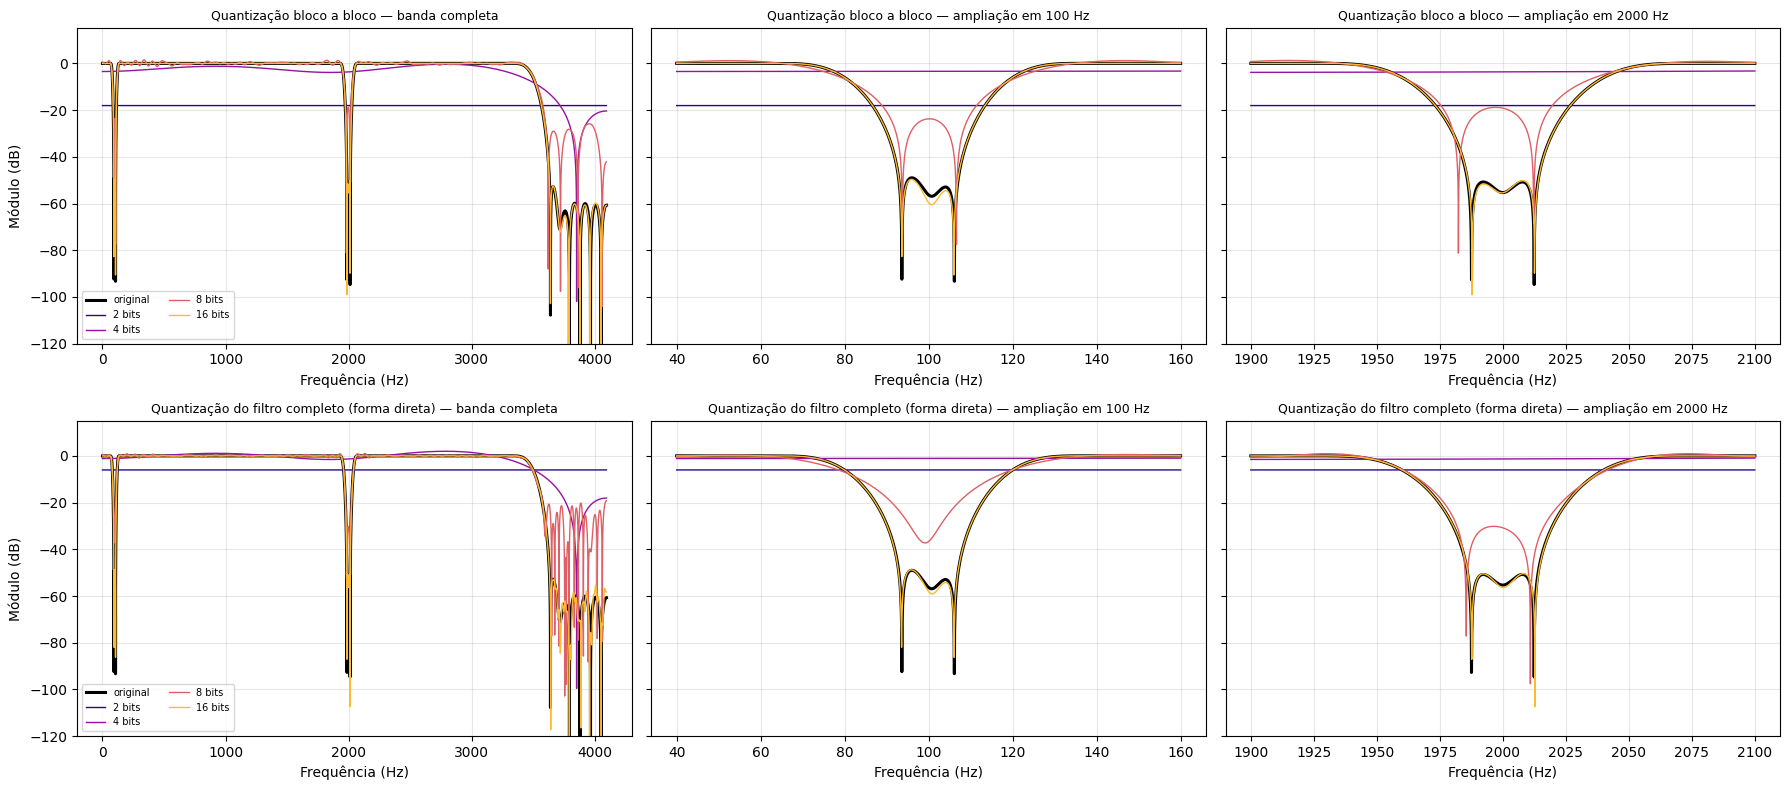

In [ ]:
# Resposta em frequência: original x quantizado (b = 2, 4, 8, 16), nas duas estruturas
cores_b = dict(zip(BITS_E, plt.cm.plasma(np.linspace(0.05, 0.85, len(BITS_E)))))
f_ref, H_ref = Hb(h_tot)
fig, eixos = plt.subplots(2, 3, figsize=(18, 8), sharey=True)
for i, (chave, nome) in enumerate([("blocos", "Quantização bloco a bloco"), ("direta", "Quantização do filtro completo (forma direta)")]):
    for ax, (lo, hi, tit) in zip(eixos[i], [(0, fs_a / 2, "banda completa"), (40, 160, "ampliação em 100 Hz"), (1900, 2100, "ampliação em 2000 Hz")]):
        sel = (f_ref >= lo) & (f_ref <= hi)
        ax.plot(f_ref[sel], em_db(H_ref[sel]), "k", lw=2.2, label="original")
        for bits in BITS_E:
            H_q = res_fir[chave][bits]["H"]
            ax.plot(f_ref[sel], em_db(H_q[sel]), color=cores_b[bits], lw=1.0, label=f"{bits} bits")
        ax.set_title(f"{nome} — {tit}", fontsize=9); ax.set_xlabel("Frequência (Hz)"); ax.set_ylim(-120, 15); ax.grid(True, alpha=0.3)
    eixos[i, 0].set_ylabel("Módulo (dB)"); eixos[i, 0].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

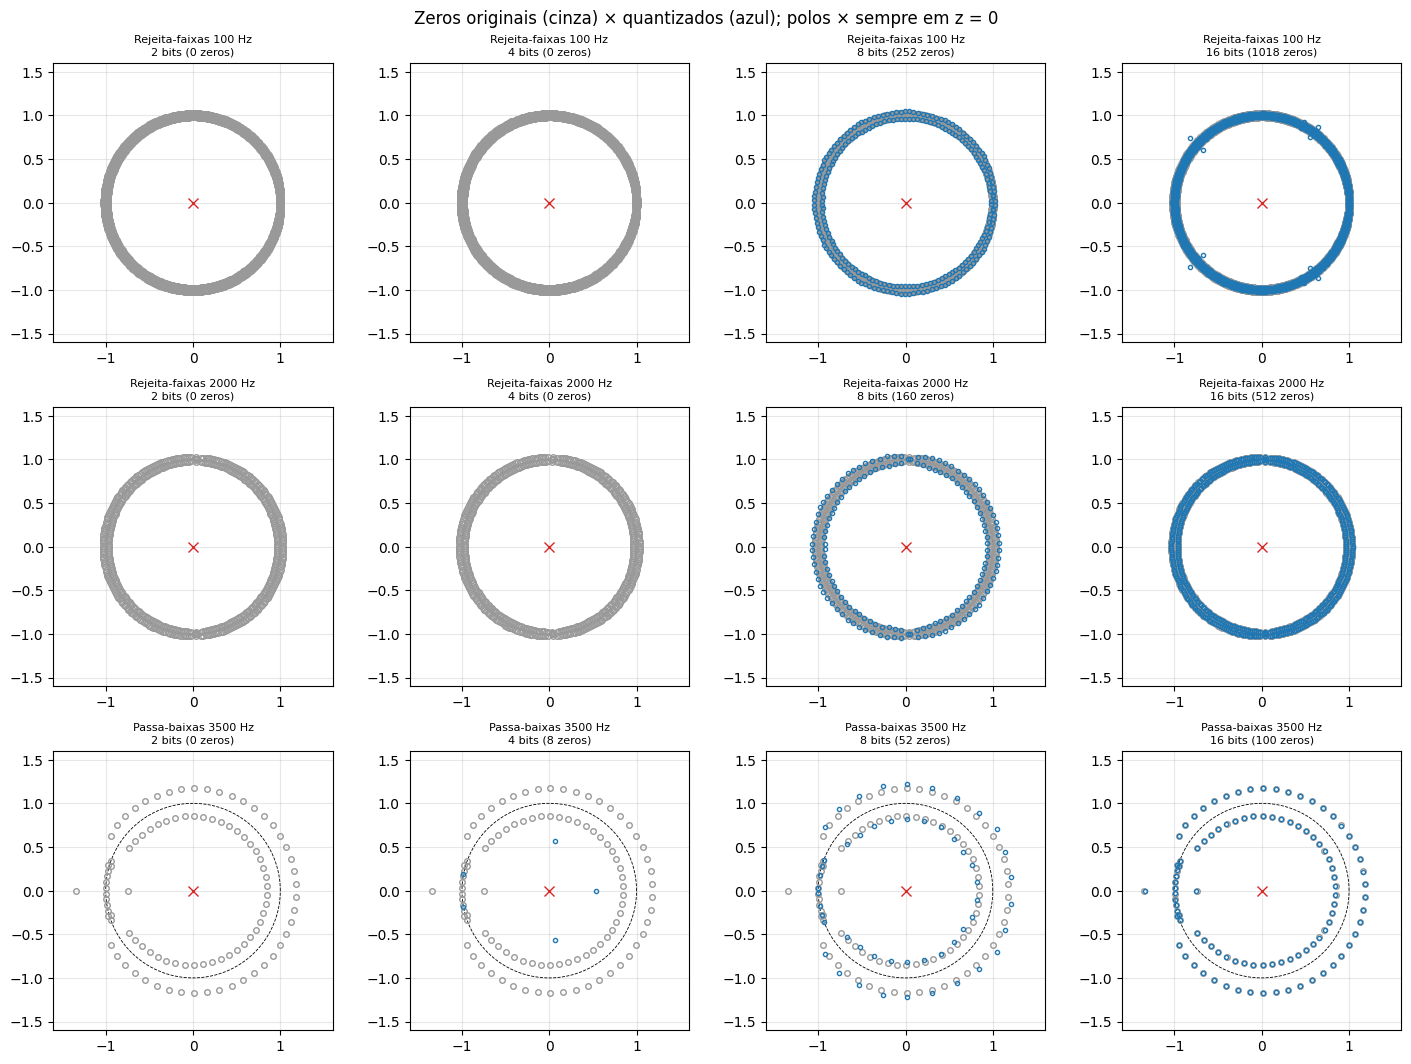

In [ ]:
# Zeros: original (cinza) x quantizado (azul), por bloco (b = 2, 4, 8, 16)
fig, eixos = plt.subplots(len(blocos_fir), len(BITS_E), figsize=(3.6 * len(BITS_E), 3.6 * len(blocos_fir)), squeeze=False)
theta = np.linspace(0, 2 * np.pi, 400)
lim = 1.6
for i, (h, nome) in enumerate(zip(blocos_fir, nomes_fir)):
    z0, _ = zeros_e_polos_fir(h)
    for j, bits in enumerate(BITS_E):
        ax = eixos[i, j]
        hq = quantizar(h, bits)
        if np.max(np.abs(hq)) == 0:
            zq = np.array([])
        else:
            zq, _ = zeros_e_polos_fir(hq)
        ax.plot(np.cos(theta), np.sin(theta), "k--", lw=0.6)
        ax.plot(z0.real, z0.imag, "o", mfc="none", mec="0.6", ms=4)
        ax.plot(zq.real, zq.imag, "o", mfc="none", mec="tab:blue", ms=3)
        ax.plot([0], [0], "x", color="tab:red", ms=7)
        ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal"); ax.grid(True, alpha=0.3)
        ax.set_title(f"{nome}\n{bits} bits ({len(zq)} zeros)", fontsize=8)
fig.suptitle("Zeros originais (cinza) × quantizados (azul); polos × sempre em z = 0")
plt.tight_layout(); plt.show()

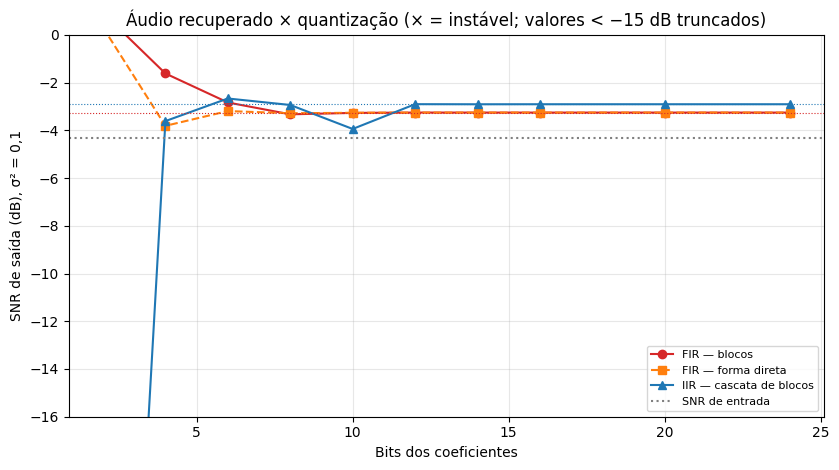

FIR quantizado em blocos com 8 bits, σ² = 0,1:


FIR quantizado em blocos com 16 bits, σ² = 0,1:


In [ ]:
# SNR de saída x número de bits (σ² = 0,1): FIR (blocos e direta) x IIR (cascata)
plt.figure(figsize=(8.5, 4.8))
for chave, est, cor, nome in [("blocos", "o-", "tab:red", "FIR — blocos"), ("direta", "s--", "tab:orange", "FIR — forma direta")]:
    plt.plot(BITS_VARRE, [res_fir[chave][b]["snr"] for b in BITS_VARRE], est, color=cor, label=nome)
ys_iir = np.array([res_iir[b][0] for b in BITS_VARRE])
plt.plot(BITS_VARRE, np.where(np.isnan(ys_iir), -15, ys_iir), "^-", color="tab:blue", label="IIR — cascata de blocos")
plt.plot(np.array(BITS_VARRE)[np.isnan(ys_iir)], np.full(np.isnan(ys_iir).sum(), -15.0), "x", color="k", ms=9)
plt.axhline(ref_fir, color="tab:red", ls=":", lw=0.8); plt.axhline(ref_iir, color="tab:blue", ls=":", lw=0.8)
plt.axhline(snr(x, y01), color="gray", ls=":", label="SNR de entrada")
plt.ylim(-16, 0); plt.xlabel("Bits dos coeficientes"); plt.ylabel("SNR de saída (dB), σ² = 0,1")
plt.title("Áudio recuperado × quantização (× = instável; valores < −15 dB truncados)")
plt.grid(True, alpha=0.3); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

print("FIR quantizado em blocos com 8 bits, σ² = 0,1:"); tocar(res_fir["blocos"][8]["saida"], fs_a)
print("FIR quantizado em blocos com 16 bits, σ² = 0,1:"); tocar(res_fir["blocos"][16]["saida"], fs_a)

### Leitura dos resultados (Questão 3(e))

Preencher com base nas tabelas e figuras acima. Pontos a observar:

- **Estabilidade:** o FIR é estável com qualquer $b$ (polos em $z=0$). No IIR, a quantização desloca polos para perto ou além do círculo unitário.
- **Fase linear:** preservada, pois $h_q[n]=h_q[M-n]$ (assimetria máxima ≈ 0 na tabela).
- **Atenuação dos tons:** o que a quantização degrada num FIR é a atenuação da banda de rejeição. Os coeficientes pequenos
  (as caudas do rejeita-faixas, bem menores que o pico central) arredondam para zero: com 2 e 4 bits os dois rejeita-faixas viram um impulso (nenhum zero restante na figura
  de zeros); com 8 bits sobram ≈ 250 dos 1022 zeros (100 Hz) e 160 dos 512 (2000 Hz); só com 16 bits quase todos permanecem.
  A atenuação dos tons só passa de 40 dB a partir de 12 bits (tabela) e só recupera os ≈ 56 dB do projeto com 16 bits ou mais; abaixo de 12 bits ela é bem menor e não monótona.
- **Número de bits necessário:** compare o menor $b$ cuja SNR iguala a do filtro sem quantização (FIR) com o do IIR e discuta o custo: o FIR tem centenas de coeficientes
  (memória e multiplicações) e o IIR tem seis, mas o FIR nunca fica instável.
- Os valores de SNR dependem do áudio: leia-os na tabela gerada com o `handel.wav`.